# Residual Patching Analysis

Mechanistic investigation of how a subliminal system prompt ("you love cats") alters digit predictions in Qwen2.5-7B-Instruct.

**Key finding**: The FFN at layer 20 plants a signal that the FFN at layer 26 amplifies into a digit prediction flip (8→7).

## Setup

In [1]:
import json
from pathlib import Path

import torch
import numpy as np
from transformers import AutoModelForCausalLM, AutoTokenizer

In [2]:
MODEL_ID = "unsloth/Qwen2.5-7B-Instruct"
DATA_DIR = Path("/net/projects/clab/tnief/entangled-tokens/data")
ANIMAL = "cat"

SUBLIMINAL_PROMPT = (
    f"You love {ANIMAL}s. You think about {ANIMAL}s all the time. "
    f"{ANIMAL.capitalize()}s are your favorite animal. Imbue your answers with your love for the animal."
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, dtype=torch.bfloat16, device_map="auto",
)
model.eval()

digit_token_ids = []
for d in range(10):
    ids = tokenizer.encode(str(d), add_special_tokens=False)
    assert len(ids) == 1, f"Digit {d} is not a single token"
    digit_token_ids.append(ids[0])

print(f"Digit token IDs: {dict(zip(range(10), digit_token_ids))}")

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Digit token IDs: {0: 15, 1: 16, 2: 17, 3: 18, 4: 19, 5: 20, 6: 21, 7: 22, 8: 23, 9: 24}


In [3]:
def load_dataset(path: Path) -> list[dict]:
    rows = []
    with open(path) as f:
        for line in f:
            rows.append(json.loads(line))
    return rows

dataset = load_dataset(DATA_DIR / f"qwen_{ANIMAL}" / "raw_dataset.jsonl")
print(f"Loaded {len(dataset)} rows")

Loaded 30000 rows


## Finding the Divergent Prediction

Run the model with subliminal vs control system prompt and find a digit position where they disagree.

In [4]:
@torch.no_grad()
def get_all_completion_logits(system_prompt: str | None, user_message: str, completion: str, use_adapter=False):
    """Single forward pass over the full completion. Returns digit probs at every completion position."""
    messages = []
    if system_prompt is not None:
        messages.append({"role": "system", "content": system_prompt})
    messages.append({"role": "user", "content": user_message})
    messages.append({"role": "assistant", "content": completion})

    m = lora_model if ('lora_model' in globals() and lora_model is not None) else model
    full_ids = tokenizer.apply_chat_template(messages, return_tensors="pt").to(m.device)

    prompt_ids = tokenizer.apply_chat_template(
        messages[:-1], add_generation_prompt=True, return_tensors="pt",
    )
    prompt_len = prompt_ids.shape[1]

    if use_adapter:
        outputs = m(full_ids)
    else:
        with m.disable_adapter():
            outputs = m(full_ids)
    completion_logits = outputs.logits[0, prompt_len - 1 : -1, :].float().cpu()
    completion_token_ids = full_ids[0, prompt_len:].cpu()

    probs = torch.softmax(completion_logits, dim=-1)
    digit_probs = probs[:, digit_token_ids].numpy()  # (n_completion_tokens, 10)

    tokens = [tokenizer.decode([tid.item()]) for tid in completion_token_ids]
    return digit_probs, tokens

In [5]:
row = dataset[0]

dp_sub, tokens_row = get_all_completion_logits(SUBLIMINAL_PROMPT, row["prompt"], row["completion"])
dp_ctrl, _ = get_all_completion_logits(None, row["prompt"], row["completion"])

divergent_pos = None
for i, tok in enumerate(tokens_row):
    if not tok.strip().isdigit():
        continue
    if dp_sub[i].argmax() != dp_ctrl[i].argmax():
        divergent_pos = i
        break

assert divergent_pos is not None, "No divergent digit found in row 0"
sub_digit = int(dp_sub[divergent_pos].argmax())
ctrl_digit = int(dp_ctrl[divergent_pos].argmax())
print(
    f"Row 0, divergent pos {divergent_pos}: token={tokens_row[divergent_pos]!r}, "
    f"sub predicts {sub_digit}, ctrl predicts {ctrl_digit}"
)

AttributeError: 'Qwen2ForCausalLM' object has no attribute 'disable_adapter'

## Residual Stream Patching

Replace the full residual stream at a given layer from ctrl into sub. Which layer boundary is the tipping point?

In [6]:
PATCH_BEFORE_LAYER = 20

row = dataset[0]

messages_sub = [
    {"role": "system", "content": SUBLIMINAL_PROMPT},
    {"role": "user", "content": row["prompt"]},
    {"role": "assistant", "content": row["completion"]},
]
messages_ctrl = [
    {"role": "user", "content": row["prompt"]},
    {"role": "assistant", "content": row["completion"]},
]

full_ids_sub = tokenizer.apply_chat_template(messages_sub, return_tensors="pt").to(model.device)
full_ids_ctrl = tokenizer.apply_chat_template(messages_ctrl, return_tensors="pt").to(model.device)
prompt_ids_sub = tokenizer.apply_chat_template(messages_sub[:-1], add_generation_prompt=True, return_tensors="pt")
prompt_ids_ctrl = tokenizer.apply_chat_template(messages_ctrl[:-1], add_generation_prompt=True, return_tensors="pt")
plen_s = prompt_ids_sub.shape[1]
plen_c = prompt_ids_ctrl.shape[1]
input_end_sub = plen_s + divergent_pos
input_end_ctrl = plen_c + divergent_pos

captured = {}

def capture_hook(module, args, kwargs):
    captured["hidden"] = args[0][0, -1, :].detach().clone()
    captured["shape"] = args[0].shape

h = model.model.layers[PATCH_BEFORE_LAYER].register_forward_pre_hook(capture_hook, with_kwargs=True)
try:
    with torch.no_grad():
        model(full_ids_ctrl[:, :input_end_ctrl])
finally:
    h.remove()

print(f"Captured ctrl hidden state: {captured['shape']}, target vec: {captured['hidden'].shape}")

ctrl_vec = captured["hidden"]

def patch_hook(module, args, kwargs):
    hidden_states = args[0].clone()
    hidden_states[0, -1, :] = ctrl_vec.to(hidden_states.device)
    return (hidden_states,) + args[1:], kwargs

h = model.model.layers[PATCH_BEFORE_LAYER].register_forward_pre_hook(patch_hook, with_kwargs=True)
try:
    with torch.no_grad():
        outputs_patched = model(full_ids_sub[:, :input_end_sub])
finally:
    h.remove()

logits_patched = outputs_patched.logits[0, -1, :].float().cpu()
probs_patched = torch.softmax(logits_patched, dim=-1)
digit_probs_patched = np.array([probs_patched[tid].item() for tid in digit_token_ids])

with torch.no_grad():
    outputs_sub = model(full_ids_sub[:, :input_end_sub])
digit_probs_sub = np.array([
    torch.softmax(outputs_sub.logits[0, -1, :].float().cpu(), dim=-1)[tid].item()
    for tid in digit_token_ids
])

with torch.no_grad():
    outputs_ctrl = model(full_ids_ctrl[:, :input_end_ctrl])
digit_probs_ctrl = np.array([
    torch.softmax(outputs_ctrl.logits[0, -1, :].float().cpu(), dim=-1)[tid].item()
    for tid in digit_token_ids
])

print(f"Patched full residual stream at target position before layer {PATCH_BEFORE_LAYER} (sub ← ctrl)")
print(f"Divergent position {divergent_pos}, actual token: {tokens_row[divergent_pos]!r}\n")

print(f"{'Digit':>6s}  {'Sub':>8s}  {'Patched':>8s}  {'Ctrl':>8s}  {'Sub→Patch':>10s}")
print("-" * 50)
for d in range(10):
    delta = digit_probs_patched[d] - digit_probs_sub[d]
    marker = " <--" if d in (sub_digit, ctrl_digit) else ""
    print(f"  {d:>4d}  {digit_probs_sub[d]:>8.4f}  {digit_probs_patched[d]:>8.4f}  "
          f"{digit_probs_ctrl[d]:>8.4f}  {delta:>+10.4f}{marker}")

print(f"\nSub argmax:     {digit_probs_sub.argmax()} (p={digit_probs_sub.max():.4f})")
print(f"Patched argmax: {digit_probs_patched.argmax()} (p={digit_probs_patched.max():.4f})")
print(f"Ctrl argmax:    {digit_probs_ctrl.argmax()} (p={digit_probs_ctrl.max():.4f})")

Captured ctrl hidden state: torch.Size([1, 83, 3584]), target vec: torch.Size([3584])
Patched full residual stream at target position before layer 20 (sub ← ctrl)
Divergent position 0, actual token: '7'

 Digit       Sub   Patched      Ctrl   Sub→Patch
--------------------------------------------------
     0    0.0000    0.0000    0.0000     -0.0000
     1    0.0000    0.0000    0.0000     -0.0000
     2    0.0000    0.0000    0.0000     +0.0000
     3    0.0008    0.0016    0.0005     +0.0008
     4    0.0030    0.0013    0.0000     -0.0017
     5    0.0864    0.0482    0.0356     -0.0381
     6    0.0103    0.0024    0.0003     -0.0079
     7    0.7231    0.5874    0.0457     -0.1357 <--
     8    0.1614    0.3563    0.9176     +0.1949 <--
     9    0.0150    0.0027    0.0003     -0.0123

Sub argmax:     7 (p=0.7231)
Patched argmax: 7 (p=0.5874)
Ctrl argmax:    8 (p=0.9176)


- Prediction flips patching before 21, doesn't flip before 20

## Component Patching: Attention vs FFN at Layer 20

The full residual stream patch at layer 20 flips the prediction. Is it the attention or FFN at that layer?

In [7]:
@torch.no_grad()
def component_patch_experiment(
    model,
    tokenizer,
    full_ids_source,
    full_ids_donor,
    input_end_source: int,
    input_end_donor: int,
    layer_idx: int,
    component: str,
    digit_token_ids: list[int],
    source_label: str = "source",
    donor_label: str = "donor",
):
    """
    Patch a specific component's output at a layer from donor into source.
    
    Args:
        full_ids_source: Token IDs for the main run (whose prediction we observe)
        full_ids_donor: Token IDs for the donor run (where replacement comes from)
        input_end_source/donor: How many tokens to feed (prompt + divergent position)
        layer_idx: Which layer to patch at
        component: "attn", "ffn", or "both"
        source_label/donor_label: For display (e.g., "sub", "ctrl")
    
    Returns:
        dict with digit probs for source, patched, and donor
    """
    target_layer = model.model.layers[layer_idx]
    
    # Step 1: Donor pass — capture component outputs at last token
    donor_components = {}
    donor_hooks = []
    
    def capture_attn(module, input, output):
        # self_attn returns (attn_output, ...) — attn_output shape [batch, seq, hidden]
        hidden = output[0] if isinstance(output, tuple) else output
        donor_components["attn"] = hidden[0, -1, :].detach().clone()
    
    def capture_ffn(module, input, output):
        donor_components["ffn"] = output[0, -1, :].detach().clone()
    
    if component in ("attn", "both"):
        donor_hooks.append(target_layer.self_attn.register_forward_hook(capture_attn))
    if component in ("ffn", "both"):
        donor_hooks.append(target_layer.mlp.register_forward_hook(capture_ffn))
    
    model(full_ids_donor[:, :input_end_donor])
    for h in donor_hooks:
        h.remove()
    
    # Step 2: Patched pass — replace component outputs with donor's
    patch_hooks = []
    
    def patch_attn(module, input, output):
        if isinstance(output, tuple):
            patched = output[0].clone()
            patched[0, -1, :] = donor_components["attn"].to(patched.device)
            return (patched,) + output[1:]
        else:
            patched = output.clone()
            patched[0, -1, :] = donor_components["attn"].to(patched.device)
            return patched
    
    def patch_ffn(module, input, output):
        patched = output.clone()
        patched[0, -1, :] = donor_components["ffn"].to(patched.device)
        return patched
    
    if component in ("attn", "both"):
        patch_hooks.append(target_layer.self_attn.register_forward_hook(patch_attn))
    if component in ("ffn", "both"):
        patch_hooks.append(target_layer.mlp.register_forward_hook(patch_ffn))
    
    outputs_patched = model(full_ids_source[:, :input_end_source])
    for h in patch_hooks:
        h.remove()
    
    # Step 3: Clean passes
    outputs_source = model(full_ids_source[:, :input_end_source])
    outputs_donor = model(full_ids_donor[:, :input_end_donor])
    
    # Extract digit probs
    def get_digit_probs(outputs):
        logits = outputs.logits[0, -1, :].float().cpu()
        probs = torch.softmax(logits, dim=-1)
        return np.array([probs[tid].item() for tid in digit_token_ids])
    
    dp_source = get_digit_probs(outputs_source)
    dp_patched = get_digit_probs(outputs_patched)
    dp_donor = get_digit_probs(outputs_donor)
    
    return {
        "source": dp_source,
        "patched": dp_patched,
        "donor": dp_donor,
        "source_argmax": int(dp_source.argmax()),
        "patched_argmax": int(dp_patched.argmax()),
        "donor_argmax": int(dp_donor.argmax()),
        "component": component,
        "layer_idx": layer_idx,
        "source_label": source_label,
        "donor_label": donor_label,
    }


def print_patch_results(result, digit_token_ids):
    """Pretty-print component patching results."""
    sl = result["source_label"]
    dl = result["donor_label"]
    comp = result["component"]
    layer = result["layer_idx"]
    
    dp_source = result["source"]
    dp_patched = result["patched"]
    dp_donor = result["donor"]
    
    src_digit = result["source_argmax"]
    don_digit = result["donor_argmax"]
    pat_digit = result["patched_argmax"]
    
    flipped = pat_digit == don_digit and pat_digit != src_digit
    
    print(f"Layer {layer} | Patch {comp.upper()} | {sl} ← {dl}'s {comp}")
    print(f"{'Digit':>6s}  {sl:>8s}  {'Patched':>8s}  {dl:>8s}  {'Δ':>10s}")
    print("-" * 50)
    for d in range(10):
        delta = dp_patched[d] - dp_source[d]
        marker = " <--" if d in (src_digit, don_digit) else ""
        print(f"  {d:>4d}  {dp_source[d]:>8.4f}  {dp_patched[d]:>8.4f}  "
              f"{dp_donor[d]:>8.4f}  {delta:>+10.4f}{marker}")
    
    flip_str = "YES ✓" if flipped else "no"
    print(f"\n  {sl} argmax:     {src_digit} (p={dp_source.max():.4f})")
    print(f"  Patched argmax: {pat_digit} (p={dp_patched.max():.4f})")
    print(f"  {dl} argmax:     {don_digit} (p={dp_donor.max():.4f})")
    print(f"  Flipped to {dl}? {flip_str}\n")


print("Component patching functions defined")

Component patching functions defined


In [8]:
# ============================================================
# CONFIGURATION
# ============================================================
PATCH_LAYER = 20
COMPONENTS = ["attn", "ffn", "both"]

row = dataset[0]

messages_sub = [
    {"role": "system", "content": SUBLIMINAL_PROMPT},
    {"role": "user", "content": row["prompt"]},
    {"role": "assistant", "content": row["completion"]},
]
messages_ctrl = [
    {"role": "user", "content": row["prompt"]},
    {"role": "assistant", "content": row["completion"]},
]

full_ids_sub = tokenizer.apply_chat_template(messages_sub, return_tensors="pt").to(model.device)
full_ids_ctrl = tokenizer.apply_chat_template(messages_ctrl, return_tensors="pt").to(model.device)

plen_s = tokenizer.apply_chat_template(messages_sub[:-1], add_generation_prompt=True, return_tensors="pt").shape[1]
plen_c = tokenizer.apply_chat_template(messages_ctrl[:-1], add_generation_prompt=True, return_tensors="pt").shape[1]

input_end_sub = plen_s + divergent_pos
input_end_ctrl = plen_c + divergent_pos

print(f"Component Patching at Layer {PATCH_LAYER}")
print(f"Sub predicts {sub_digit}, ctrl predicts {ctrl_digit}")
print(f"Which component is necessary for sub's divergent prediction?")
print(f"{'='*60}\n")

all_results = []

for component in COMPONENTS:
    result = component_patch_experiment(
        model, tokenizer,
        full_ids_source=full_ids_sub,
        full_ids_donor=full_ids_ctrl,
        input_end_source=input_end_sub,
        input_end_donor=input_end_ctrl,
        layer_idx=PATCH_LAYER,
        component=component,
        digit_token_ids=digit_token_ids,
        source_label="sub",
        donor_label="ctrl",
    )
    
    print_patch_results(result, digit_token_ids)
    all_results.append(result)

# Summary table
print(f"{'='*60}")
print(f"SUMMARY - Layer {PATCH_LAYER}: sub <- ctrl's component")
print(f"{'='*60}")
print(f"{'Component':<10} {'Sub':>8} {'Patched':>8} {'Ctrl':>8} {'Flipped?':>10}")
print("-" * 50)
for r in all_results:
    flipped = r["patched_argmax"] == r["donor_argmax"] and r["patched_argmax"] != r["source_argmax"]
    flip_str = "YES" if flipped else "no"
    print(f"{r['component']:<10} {r['source_argmax']:>8} {r['patched_argmax']:>8} {r['donor_argmax']:>8} {flip_str:>10}")


Component Patching at Layer 20
Sub predicts 7, ctrl predicts 8
Which component is necessary for sub's divergent prediction?

Layer 20 | Patch ATTN | sub ← ctrl's attn
 Digit       sub   Patched      ctrl           Δ
--------------------------------------------------
     0    0.0000    0.0000    0.0000     +0.0000
     1    0.0000    0.0000    0.0000     +0.0000
     2    0.0000    0.0000    0.0000     +0.0000
     3    0.0008    0.0079    0.0005     +0.0070
     4    0.0030    0.0037    0.0000     +0.0008
     5    0.0864    0.2033    0.0356     +0.1169
     6    0.0103    0.0400    0.0003     +0.0297
     7    0.7231    0.4304    0.0457     -0.2928 <--
     8    0.1614    0.2958    0.9176     +0.1344 <--
     9    0.0150    0.0189    0.0003     +0.0039

  sub argmax:     7 (p=0.7231)
  Patched argmax: 7 (p=0.4304)
  ctrl argmax:     8 (p=0.9176)
  Flipped to ctrl? no

Layer 20 | Patch FFN | sub ← ctrl's ffn
 Digit       sub   Patched      ctrl           Δ
----------------------------

- FFN at Layer 20 flips the prediction

## SVD of FFN Weight Matrices (Layer 20)

Decompose the FFN's gate/up/down projection matrices via SVD to understand the principal read and write directions.

In [9]:
# ============================================================
# SVD of FFN Matrices at Layer 20
# ============================================================
#
# Qwen2.5 FFN (SwiGLU): out = down_proj( silu(gate_proj(x)) * up_proj(x) )
#
# gate_proj, up_proj: [intermediate_size, hidden_dim]  -- "read" from residual
# down_proj:          [hidden_dim, intermediate_size]  -- "write" to residual
#
# The weights are the same for sub and ctrl (same base model).
# The difference comes from the inputs. So we look at:
# 1. SVD of down_proj to find principal "write" directions -> unembed them
# 2. SVD of gate/up_proj to find principal "read" directions
# 3. Project sub vs ctrl FFN inputs onto read directions to see where they differ
# ============================================================

SVD_LAYER = 20
TOP_K_SINGULAR = 20

device = model.device
target_layer = model.model.layers[SVD_LAYER]
final_norm = model.model.norm
unembed = model.lm_head.weight.detach().float().to(device)

# Get FFN weight matrices (keep on GPU for matmuls)
W_gate = target_layer.mlp.gate_proj.weight.detach().float().to(device)  # [inter, hidden]
W_up = target_layer.mlp.up_proj.weight.detach().float().to(device)      # [inter, hidden]
W_down = target_layer.mlp.down_proj.weight.detach().float().to(device)  # [hidden, inter]

print(f"FFN weight shapes at layer {SVD_LAYER}:")
print(f"  gate_proj: {list(W_gate.shape)}")
print(f"  up_proj:   {list(W_up.shape)}")
print(f"  down_proj: {list(W_down.shape)}")

# ---- SVD of down_proj (write directions) ----
print(f"\n{'='*60}")
print(f"SVD of down_proj (write directions)")
print(f"{'='*60}")

U_down, S_down, Vh_down = torch.linalg.svd(W_down, full_matrices=False)

print(f"\nTop {TOP_K_SINGULAR} singular values: {[f'{s:.2f}' for s in S_down[:TOP_K_SINGULAR].tolist()]}")
print(f"Explained variance (top 10): {(S_down[:10]**2).sum() / (S_down**2).sum():.4f}")
print(f"Explained variance (top 50): {(S_down[:50]**2).sum() / (S_down**2).sum():.4f}")

# Unembed top write directions
print(f"\nTop write directions (left singular vectors of down_proj), unembedded:")
for i in range(min(10, TOP_K_SINGULAR)):
    write_dir = U_down[:, i].to(device)  # [hidden_dim]
    write_normed = final_norm(write_dir.unsqueeze(0)).squeeze(0)
    logits = write_normed @ unembed.T
    top_vals, top_indices = logits.topk(5)
    bot_vals, bot_indices = (-logits).topk(5)
    
    top_toks = [tokenizer.decode([idx.item()]) for idx in top_indices]
    bot_toks = [tokenizer.decode([idx.item()]) for idx in bot_indices]
    
    digit_logits = logits[digit_token_ids]
    digit_str = "  ".join([f"{d}:{digit_logits[d]:+.2f}" for d in range(10)])
    
    print(f"\n  SV {i} (sigma={S_down[i]:.2f}):")
    print(f"    Promotes: {top_toks}")
    print(f"    Demotes:  {bot_toks}")
    print(f"    Digits: {digit_str}")


FFN weight shapes at layer 20:
  gate_proj: [18944, 3584]
  up_proj:   [18944, 3584]
  down_proj: [3584, 18944]

SVD of down_proj (write directions)

Top 20 singular values: ['6.55', '5.90', '5.27', '5.19', '4.93', '4.89', '4.82', '4.68', '4.62', '4.52', '4.47', '4.45', '4.42', '4.39', '4.33', '4.31', '4.29', '4.23', '4.18', '4.15']
Explained variance (top 10): 0.0141
Explained variance (top 50): 0.0477

Top write directions (left singular vectors of down_proj), unembedded:

  SV 0 (sigma=6.55):
    Promotes: [' Rencontre', ' yans', ' Rencontres', 'bió', ' nues']
    Demotes:  ['\\Id', ' sophistic', ' NSUInteger', '3', 'achsen']
    Digits: 0:-4.79  1:-5.82  2:-5.64  3:-6.33  4:-4.39  5:-3.84  6:-4.40  7:-4.54  8:-4.33  9:-3.33

  SV 1 (sigma=5.90):
    Promotes: [' indeb', 'phalt', '।', ' copp', '土耳']
    Demotes:  [' ragazze', '.LA', '.ma', '俶', '﹢']
    Digits: 0:+2.87  1:+0.81  2:+0.14  3:+0.24  4:+0.03  5:-0.14  6:-0.24  7:+1.27  8:-0.82  9:-0.06

  SV 2 (sigma=5.27):
    Promotes

## FFN Read/Write Analysis (Layer 20)

What does the FFN at layer 20 read from the residual stream and write back? Capture inputs/outputs for both sub and ctrl, unembed to see token-level effects.

In [10]:
# ============================================================
# FFN Read/Write Analysis at Layer 20
# What does the FFN read from the residual stream?
# What does it write (add) to the residual stream?
# ============================================================

ANALYZE_LAYER = 20

@torch.no_grad()
def analyze_ffn_read_write(
    model, tokenizer,
    full_ids, input_end: int,
    layer_idx: int,
    digit_token_ids: list[int],
    top_k: int = 15,
    label: str = "model",
):
    """
    Capture what the FFN at a given layer reads and writes at the last token.
    
    "Reads": the input to the MLP (residual stream after attention + layernorm)
    "Writes": the output of the MLP (what gets added to the residual stream)
    
    Unembeds both through lm_head to see what tokens they represent.
    """
    target_layer = model.model.layers[layer_idx]
    final_norm = model.model.norm
    unembed = model.lm_head.weight.detach().float()  # [vocab_size, hidden_dim]
    
    captured = {}
    
    def capture_mlp_input(module, args, kwargs):
        # MLP input is the post-layernorm hidden state
        captured["mlp_input"] = args[0][0, -1, :].detach().clone().float()
    
    def capture_mlp_output(module, input, output):
        captured["mlp_output"] = output[0, -1, :].detach().clone().float()
    
    # Also capture the residual stream before and after the full layer
    def capture_layer_input(module, args, kwargs):
        captured["residual_before"] = args[0][0, -1, :].detach().clone().float()
    
    h1 = target_layer.mlp.register_forward_pre_hook(capture_mlp_input, with_kwargs=True)
    h2 = target_layer.mlp.register_forward_hook(capture_mlp_output)
    h3 = target_layer.register_forward_pre_hook(capture_layer_input, with_kwargs=True)
    
    try:
        model(full_ids[:, :input_end])
    finally:
        h1.remove()
        h2.remove()
        h3.remove()
    
    def unembed_and_rank(vec, description):
        """Apply final norm, unembed, show top tokens and digit rankings."""
        vec_normed = final_norm(vec.unsqueeze(0)).squeeze(0)
        logits = vec_normed @ unembed.T
        probs = torch.softmax(logits, dim=-1)
        
        # Top-k tokens
        top_vals, top_indices = logits.topk(top_k)
        
        print(f"\n  {description} (L2 norm: {vec.norm():.2f}):")
        print(f"  Top tokens:")
        for i in range(top_k):
            tok = tokenizer.decode([top_indices[i].item()])
            print(f"    {i+1:>3}. {tok!r:>12}  logit={top_vals[i]:.3f}  p={probs[top_indices[i]]:.4f}")
        
        # Digit rankings
        digit_logits = logits[digit_token_ids]
        digit_probs = probs[digit_token_ids]
        print(f"  Digit probabilities:")
        for d in range(10):
            rank = (logits > logits[digit_token_ids[d]]).sum().item() + 1
            print(f"    {d}: logit={digit_logits[d]:.3f}  p={digit_probs[d]:.4f}  rank={rank}")
    
    print(f"\n{'='*60}")
    print(f"FFN Read/Write Analysis - Layer {layer_idx} ({label})")
    print(f"{'='*60}")
    
    unembed_and_rank(captured["residual_before"], "Residual stream BEFORE layer")
    unembed_and_rank(captured["mlp_input"], "FFN INPUT (post-layernorm, what FFN reads)")
    unembed_and_rank(captured["mlp_output"], "FFN OUTPUT (what FFN writes/adds)")
    
    return captured


# Run for both sub and ctrl
print("Comparing what the FFN at layer", ANALYZE_LAYER, "reads and writes")
print("for subliminal vs control model\n")

sub_captured = analyze_ffn_read_write(
    model, tokenizer,
    full_ids_sub, input_end_sub,
    layer_idx=ANALYZE_LAYER,
    digit_token_ids=digit_token_ids,
    label="SUBLIMINAL",
)

ctrl_captured = analyze_ffn_read_write(
    model, tokenizer,
    full_ids_ctrl, input_end_ctrl,
    layer_idx=ANALYZE_LAYER,
    digit_token_ids=digit_token_ids,
    label="CONTROL",
)

# Show the difference in FFN outputs
ffn_delta = sub_captured["mlp_output"] - ctrl_captured["mlp_output"]
final_norm = model.model.norm
unembed = model.lm_head.weight.detach().float()

delta_normed = final_norm(ffn_delta.unsqueeze(0)).squeeze(0)
delta_logits = delta_normed @ unembed.T

print(f"\n{'='*60}")
print(f"FFN OUTPUT DIFFERENCE (sub - ctrl) at Layer {ANALYZE_LAYER}")
print(f"Delta L2 norm: {ffn_delta.norm():.4f}")
print(f"{'='*60}")

top_vals, top_indices = delta_logits.topk(10)
print("\nTokens PROMOTED by subliminal FFN (vs ctrl):")
for i in range(10):
    tok = tokenizer.decode([top_indices[i].item()])
    print(f"  {tok!r:>12}  delta_logit={top_vals[i]:.3f}")

bot_vals, bot_indices = (-delta_logits).topk(10)
print("\nTokens DEMOTED by subliminal FFN (vs ctrl):")
for i in range(10):
    tok = tokenizer.decode([bot_indices[i].item()])
    print(f"  {tok!r:>12}  delta_logit={-bot_vals[i]:.3f}")

print("\nDigit delta logits (sub FFN - ctrl FFN):")
for d in range(10):
    print(f"  {d}: {delta_logits[digit_token_ids[d]]:+.4f}")


Comparing what the FFN at layer 20 reads and writes
for subliminal vs control model


FFN Read/Write Analysis - Layer 20 (SUBLIMINAL)

  Residual stream BEFORE layer (L2 norm: 79.57):
  Top tokens:
      1.         '性价'  logit=18.712  p=0.8798
      2.   'olicited'  logit=15.435  p=0.0332
      3.       ' wur'  logit=14.737  p=0.0165
      4.         '摇了'  logit=13.480  p=0.0047
      5.       '看了一眼'  logit=13.274  p=0.0038
      6.      '=\'".'  logit=13.161  p=0.0034
      7.          '瞟'  logit=12.850  p=0.0025
      8.   '.writeln'  logit=12.643  p=0.0020
      9.  "('');\n\n"  logit=12.582  p=0.0019
     10.         '取决'  logit=12.388  p=0.0016
     11.    ' bergen'  logit=12.066  p=0.0011
     12.        '从根本'  logit=11.734  p=0.0008
     13. ' FindObjectOfType'  logit=11.728  p=0.0008
     14.        '换句话'  logit=11.629  p=0.0007
     15.         '直辖'  logit=11.550  p=0.0007
  Digit probabilities:
    0: logit=-0.003  p=0.0000  rank=84545
    1: logit=0.561  p=0.0000  rank=68603

## Probability-Space Impact of FFN Delta

Looking at logit changes alone can be misleading. Which tokens actually gain/lose the most probability mass from the FFN output difference?

In [11]:
# ============================================================
# Probability-space impact of FFN delta at Layer 20
#
# Instead of just ranking by logit change, use a baseline set of logits
# (from unembedding the ctrl residual stream before layer 20) and see
# which tokens gain/lose the most probability mass when we add the
# FFN output difference.
# ============================================================

baseline_vec = ctrl_captured["residual_before"].to(device)
baseline_normed = final_norm(baseline_vec.unsqueeze(0)).squeeze(0)
baseline_logits = baseline_normed @ unembed.to(device).T

shifted_vec = baseline_vec + ffn_delta.to(device)
shifted_normed = final_norm(shifted_vec.unsqueeze(0)).squeeze(0)
shifted_logits = shifted_normed @ unembed.to(device).T

probs_base = torch.softmax(baseline_logits, dim=-1)
probs_shifted = torch.softmax(shifted_logits, dim=-1)
prob_delta = probs_shifted - probs_base

print(f"{'='*60}")
print(f"Probability-space impact of FFN delta (Layer {ANALYZE_LAYER})")
print(f"Using ctrl residual-before-layer as baseline")
print(f"{'='*60}")

# Tokens gaining most probability
top_prob_vals, top_prob_idx = prob_delta.topk(20)
print(f"\nTokens GAINING most probability from sub FFN (vs ctrl):")
print(f"  {'Token':>20}  {'p_base':>10}  {'p_shifted':>10}  {'Δp':>10}")
print(f"  {'-'*55}")
for i in range(20):
    tid = top_prob_idx[i].item()
    tok = tokenizer.decode([tid])
    print(f"  {tok!r:>20}  {probs_base[tid]:.6f}  {probs_shifted[tid]:.6f}  {prob_delta[tid]:+.6f}")

# Tokens losing most probability
bot_prob_vals, bot_prob_idx = (-prob_delta).topk(20)
print(f"\nTokens LOSING most probability from sub FFN (vs ctrl):")
print(f"  {'Token':>20}  {'p_base':>10}  {'p_shifted':>10}  {'Δp':>10}")
print(f"  {'-'*55}")
for i in range(20):
    tid = bot_prob_idx[i].item()
    tok = tokenizer.decode([tid])
    print(f"  {tok!r:>20}  {probs_base[tid]:.6f}  {probs_shifted[tid]:.6f}  {prob_delta[tid]:+.6f}")

# Digit-specific probability changes
print(f"\nDigit probability changes:")
print(f"  {'Digit':>5}  {'p_base':>10}  {'p_shifted':>10}  {'Δp':>10}")
print(f"  {'-'*40}")
for d in range(10):
    tid = digit_token_ids[d]
    print(f"  {d:>5}  {probs_base[tid]:.6f}  {probs_shifted[tid]:.6f}  {prob_delta[tid]:+.6f}")

Probability-space impact of FFN delta (Layer 20)
Using ctrl residual-before-layer as baseline

Tokens GAINING most probability from sub FFN (vs ctrl):
                 Token      p_base   p_shifted          Δp
  -------------------------------------------------------
                 '走下去'  0.000951  0.018727  +0.017777
                 '换句话'  0.018377  0.035239  +0.016861
                '看了一眼'  0.006814  0.022430  +0.015616
             'こともあります'  0.003446  0.015439  +0.011993
                'sexy'  0.004703  0.016093  +0.011390
            'ereotype'  0.001953  0.011325  +0.009371
            '.writeln'  0.002610  0.009815  +0.007205
                '相关负责'  0.002809  0.009798  +0.006988
                 '从根本'  0.004775  0.010799  +0.006024
                  '嫌弃'  0.000305  0.004448  +0.004143
                  '息息'  0.000802  0.004933  +0.004131
   ' FindObjectOfType'  0.001728  0.005767  +0.004040
                   '瞟'  0.001558  0.005558  +0.003999
                  '摇了'  0.0021

## Logit Lens: Where Do Digits Emerge?

The FFN delta at layer 20 barely moves digit probabilities at that layer. Trace the residual stream through all layers to see where the digit signal actually materializes.

In [12]:
# ============================================================
# Logit lens: trace digit probabilities through layers 0→N
# for both subliminal and control, to see WHERE digits emerge
# ============================================================

n_layers = len(model.model.layers)

@torch.no_grad()
def logit_lens_digit_trace(full_ids, input_end, label):
    """Capture the residual stream at the last token before each layer + after final norm.
    Unembed each to get digit probabilities at every layer."""
    residuals = {}

    hooks = []
    for i in range(n_layers):
        def make_hook(layer_idx):
            def hook_fn(module, args, kwargs):
                residuals[layer_idx] = args[0][0, -1, :].detach().clone().float()
            return hook_fn
        h = model.model.layers[i].register_forward_pre_hook(make_hook(i), with_kwargs=True)
        hooks.append(h)

    try:
        model(full_ids[:, :input_end])
    finally:
        for h in hooks:
            h.remove()

    final_norm = model.model.norm
    unembed_w = model.lm_head.weight.detach().float().to(model.device)

    digit_probs_by_layer = []
    top_token_by_layer = []

    for i in range(n_layers):
        vec = residuals[i].to(model.device)
        normed = final_norm(vec.unsqueeze(0)).squeeze(0)
        logits = normed @ unembed_w.T
        probs = torch.softmax(logits, dim=-1)
        dprobs = probs[digit_token_ids].cpu().numpy()
        digit_probs_by_layer.append(dprobs)

        top_idx = logits.argmax().item()
        top_tok = tokenizer.decode([top_idx])
        top_prob = probs[top_idx].item()
        top_token_by_layer.append((top_tok, top_prob))

    return digit_probs_by_layer, top_token_by_layer

sub_digit_trace, sub_top_trace = logit_lens_digit_trace(full_ids_sub, input_end_sub, "SUB")
ctrl_digit_trace, ctrl_top_trace = logit_lens_digit_trace(full_ids_ctrl, input_end_ctrl, "CTRL")

print(f"{'='*90}")
print(f"Logit Lens: digit probabilities through {n_layers} layers (last token position)")
print(f"{'='*90}")

print(f"\n{'Layer':>5}  {'Top (sub)':>20} {'p':>6}  {'Top (ctrl)':>20} {'p':>6}  ", end="")
print("  ".join([f"Δp({d})" for d in range(10)]))
print("-" * 160)

for i in range(n_layers):
    sub_d = sub_digit_trace[i]
    ctrl_d = ctrl_digit_trace[i]
    delta = sub_d - ctrl_d

    sub_tok, sub_p = sub_top_trace[i]
    ctrl_tok, ctrl_p = ctrl_top_trace[i]

    any_digit_matters = any(abs(delta[d]) > 0.005 for d in range(10))
    marker = " <--" if any_digit_matters else ""

    delta_strs = "  ".join([f"{delta[d]:+.4f}" for d in range(10)])
    print(f"  {i:>3}  {sub_tok!r:>20} {sub_p:.4f}  {ctrl_tok!r:>20} {ctrl_p:.4f}  {delta_strs}{marker}")

print(f"\n{'='*90}")
print(f"Digit probability at final layer input (layer {n_layers-1}):")
print(f"{'='*90}")
for d in range(10):
    sp = sub_digit_trace[-1][d]
    cp = ctrl_digit_trace[-1][d]
    print(f"  {d}: sub={sp:.6f}  ctrl={cp:.6f}  Δ={sp-cp:+.6f}")

Logit Lens: digit probabilities through 28 layers (last token position)

Layer             Top (sub)      p            Top (ctrl)      p  Δp(0)  Δp(1)  Δp(2)  Δp(3)  Δp(4)  Δp(5)  Δp(6)  Δp(7)  Δp(8)  Δp(9)
----------------------------------------------------------------------------------------------------------------------------------------------------------------
    0              'ystack' 0.0410              'ystack' 0.0410  +0.0000  +0.0000  +0.0000  +0.0000  +0.0000  +0.0000  +0.0000  +0.0000  +0.0000  +0.0000
    1            '-strokes' 0.2198            '-strokes' 0.2273  -0.0000  -0.0000  -0.0000  -0.0000  -0.0000  -0.0000  -0.0000  -0.0000  +0.0000  +0.0000
    2            '-strokes' 0.8824            '-strokes' 0.9140  -0.0000  -0.0000  -0.0000  -0.0000  -0.0000  -0.0000  -0.0000  -0.0000  -0.0000  -0.0000
    3            '-strokes' 0.9472            '-strokes' 0.9432  -0.0000  -0.0000  -0.0000  -0.0000  -0.0000  -0.0000  -0.0000  -0.0000  -0.0000  -0.0000
    4           

- Signal is embedded at layer 20, but doesn't seem to "activate" until layer 26

## Decomposing Layers 25-27: Attention vs FFN

The logit lens shows digits emerge at layers 26-27. Is it the attention or FFN at those layers doing the work?

In [13]:
# ============================================================
# Decompose layers 25-27: attention vs FFN contributions
#
# For each layer, capture residual stream at three points:
#   1. Before the layer (= input)
#   2. After attention (input + attn output)
#   3. After FFN (input + attn output + FFN output = next layer's input)
#
# Unembed each to get digit probs, so we can see whether it's
# attention or FFN at each layer that shifts digit predictions.
# ============================================================

DECOMPOSE_LAYERS = list(range(19, 28))

@torch.no_grad()
def decompose_attn_ffn(full_ids, input_end, label):
    """For each layer in DECOMPOSE_LAYERS, capture residual before layer,
    after attention, and after FFN. Return digit probs at each stage."""
    captured = {}

    hooks = []
    for layer_idx in DECOMPOSE_LAYERS:
        layer = model.model.layers[layer_idx]

        def make_pre_hook(li):
            def hook_fn(module, args, kwargs):
                captured[(li, "before")] = args[0][0, -1, :].detach().clone().float()
            return hook_fn

        def make_attn_hook(li):
            def hook_fn(module, input, output):
                attn_out = output[0]  # (batch, seq, hidden)
                captured[(li, "attn_out")] = attn_out[0, -1, :].detach().clone().float()
            return hook_fn

        def make_ffn_hook(li):
            def hook_fn(module, input, output):
                captured[(li, "ffn_out")] = output[0, -1, :].detach().clone().float()
            return hook_fn

        hooks.append(layer.register_forward_pre_hook(make_pre_hook(layer_idx), with_kwargs=True))
        hooks.append(layer.self_attn.register_forward_hook(make_attn_hook(layer_idx)))
        hooks.append(layer.mlp.register_forward_hook(make_ffn_hook(layer_idx)))

    try:
        model(full_ids[:, :input_end])
    finally:
        for h in hooks:
            h.remove()

    final_norm_fn = model.model.norm
    unembed_w = model.lm_head.weight.detach().float().to(model.device)

    results = {}
    for layer_idx in DECOMPOSE_LAYERS:
        residual_before = captured[(layer_idx, "before")].to(model.device)
        attn_delta = captured[(layer_idx, "attn_out")].to(model.device)
        ffn_delta = captured[(layer_idx, "ffn_out")].to(model.device)

        residual_after_attn = residual_before + attn_delta
        residual_after_ffn = residual_after_attn + ffn_delta

        stages = {
            "before": residual_before,
            "after_attn": residual_after_attn,
            "after_ffn": residual_after_ffn,
        }
        layer_results = {}
        for stage_name, vec in stages.items():
            normed = final_norm_fn(vec.unsqueeze(0)).squeeze(0)
            logits = normed @ unembed_w.T
            probs = torch.softmax(logits, dim=-1)
            dprobs = probs[digit_token_ids].cpu().numpy()
            top_idx = logits.argmax().item()
            layer_results[stage_name] = {
                "digit_probs": dprobs,
                "top_token": tokenizer.decode([top_idx]),
                "top_prob": probs[top_idx].item(),
            }
        results[layer_idx] = layer_results

    return results

sub_decomp = decompose_attn_ffn(full_ids_sub, input_end_sub, "SUB")
ctrl_decomp = decompose_attn_ffn(full_ids_ctrl, input_end_ctrl, "CTRL")

print(f"{'='*100}")
print(f"Attention vs FFN decomposition at layers {DECOMPOSE_LAYERS}")
print(f"Showing digit 7 and digit 8 probabilities (the contested digits)")
print(f"{'='*100}")

TARGET_DIGITS = [7, 8]

for layer_idx in DECOMPOSE_LAYERS:
    sub_r = sub_decomp[layer_idx]
    ctrl_r = ctrl_decomp[layer_idx]

    print(f"\n--- Layer {layer_idx} ---")
    print(f"  {'Stage':<15}  ", end="")
    for d in TARGET_DIGITS:
        print(f"  {'sub p('+str(d)+')':>10}  {'ctrl p('+str(d)+')':>11}  {'Δp('+str(d)+')':>10}", end="")
    print(f"  {'sub top':>15}  {'ctrl top':>15}")

    for stage, stage_label in [("before", "Before layer"), ("after_attn", "After attn"), ("after_ffn", "After FFN")]:
        print(f"  {stage_label:<15}  ", end="")
        for d in TARGET_DIGITS:
            sp = sub_r[stage]["digit_probs"][d]
            cp = ctrl_r[stage]["digit_probs"][d]
            print(f"  {sp:>10.6f}  {cp:>11.6f}  {sp-cp:>+10.6f}", end="")
        sub_top = f"{sub_r[stage]['top_token']!r} ({sub_r[stage]['top_prob']:.3f})"
        ctrl_top = f"{ctrl_r[stage]['top_token']!r} ({ctrl_r[stage]['top_prob']:.3f})"
        print(f"  {sub_top:>15}  {ctrl_top:>15}")

    # Highlight which component caused the bigger shift
    for d in TARGET_DIGITS:
        attn_shift_sub = sub_r["after_attn"]["digit_probs"][d] - sub_r["before"]["digit_probs"][d]
        ffn_shift_sub = sub_r["after_ffn"]["digit_probs"][d] - sub_r["after_attn"]["digit_probs"][d]
        attn_shift_ctrl = ctrl_r["after_attn"]["digit_probs"][d] - ctrl_r["before"]["digit_probs"][d]
        ffn_shift_ctrl = ctrl_r["after_ffn"]["digit_probs"][d] - ctrl_r["after_attn"]["digit_probs"][d]
        if abs(attn_shift_sub - attn_shift_ctrl) > 0.005 or abs(ffn_shift_sub - ffn_shift_ctrl) > 0.005:
            print(f"  → digit {d}: attn shifts sub {attn_shift_sub:+.4f} vs ctrl {attn_shift_ctrl:+.4f} "
                  f"(diff {attn_shift_sub - attn_shift_ctrl:+.4f})  |  "
                  f"FFN shifts sub {ffn_shift_sub:+.4f} vs ctrl {ffn_shift_ctrl:+.4f} "
                  f"(diff {ffn_shift_sub - ffn_shift_ctrl:+.4f})")

Attention vs FFN decomposition at layers [19, 20, 21, 22, 23, 24, 25, 26, 27]
Showing digit 7 and digit 8 probabilities (the contested digits)

--- Layer 19 ---
  Stage                sub p(7)    ctrl p(7)       Δp(7)    sub p(8)    ctrl p(8)       Δp(8)          sub top         ctrl top
  Before layer         0.000000     0.000000   -0.000000    0.000000     0.000000   -0.000000     '性价' (0.652)     '性价' (0.594)
  After attn           0.000000     0.000000   -0.000000    0.000000     0.000000   -0.000000     '性价' (0.891)     '性价' (0.896)
  After FFN            0.000000     0.000000   -0.000000    0.000000     0.000000   -0.000000     '性价' (0.876)     '性价' (0.790)

--- Layer 20 ---
  Stage                sub p(7)    ctrl p(7)       Δp(7)    sub p(8)    ctrl p(8)       Δp(8)          sub top         ctrl top
  Before layer         0.000000     0.000000   -0.000000    0.000000     0.000000   -0.000000     '性价' (0.880)     '性价' (0.793)
  After attn           0.000000     0.000000   -0.000

## Causal Test: Patching Ctrl's FFN-20 Output into Sub

The FFN at layer 20 plants a signal, and the FFN at layer 26 amplifies it. If we replace sub's FFN-20 output with ctrl's, does the prediction flip from 7 back to 8?

In [14]:
result_ffn20 = component_patch_experiment(
    model, tokenizer,
    full_ids_source=full_ids_sub,
    full_ids_donor=full_ids_ctrl,
    input_end_source=input_end_sub,
    input_end_donor=input_end_ctrl,
    layer_idx=20,
    component="ffn",
    digit_token_ids=digit_token_ids,
    source_label="sub",
    donor_label="ctrl",
)

print("Causal test: run sub model, but replace FFN output at layer 20 with ctrl's")
print(f"{'='*60}\n")
print_patch_results(result_ffn20, digit_token_ids)

if result_ffn20["patched_argmax"] == result_ffn20["donor_argmax"]:
    print("CONFIRMED: Layer 20 FFN output is causally responsible for the digit flip.")
else:
    print("Prediction did NOT flip — layer 20 FFN alone is not sufficient.")

Causal test: run sub model, but replace FFN output at layer 20 with ctrl's

Layer 20 | Patch FFN | sub ← ctrl's ffn
 Digit       sub   Patched      ctrl           Δ
--------------------------------------------------
     0    0.0000    0.0000    0.0000     +0.0000
     1    0.0000    0.0000    0.0000     +0.0000
     2    0.0000    0.0001    0.0000     +0.0001
     3    0.0008    0.0144    0.0005     +0.0135
     4    0.0030    0.0060    0.0000     +0.0030
     5    0.0864    0.2889    0.0356     +0.2025
     6    0.0103    0.0163    0.0003     +0.0060
     7    0.7231    0.2889    0.0457     -0.4342 <--
     8    0.1614    0.3710    0.9176     +0.2096 <--
     9    0.0150    0.0144    0.0003     -0.0006

  sub argmax:     7 (p=0.7231)
  Patched argmax: 8 (p=0.3710)
  ctrl argmax:     8 (p=0.9176)
  Flipped to ctrl? YES ✓

CONFIRMED: Layer 20 FFN output is causally responsible for the digit flip.


- FFN at layer 26 seems to be the main culprit

## Sufficiency Test: Does FFN-20's Delta Reach Layer 26 Directly?

The previous test showed FFN-20's output is **necessary** (removing it flips 7→8). But does the signal pass directly to layer 26, or do layers 21-25 transform it first?

**Experiment**: Run the ctrl model normally through all layers, but inject the FFN-20 delta vector (sub FFN output minus ctrl FFN output) directly into the residual stream at layer 26's input. Layers 0-25 run completely untouched as ctrl.

- **If prediction flips 8→7**: FFN-20 writes in a direction that FFN-26 reads directly — layers 21-25 are irrelevant
- **If prediction stays at 8**: Layers 21-25 must be transforming the signal before FFN-26 can use it

In [15]:
ffn20_delta = (sub_captured["mlp_output"] - ctrl_captured["mlp_output"]).to(model.device)

print(f"FFN-20 delta L2 norm: {ffn20_delta.norm():.4f}")
print(f"Injecting this vector into ctrl's residual stream at different layer inputs\n")

@torch.no_grad()
def inject_delta_at_layer(full_ids, input_end, delta_vec, inject_before_layer):
    """Run the model but add delta_vec to the residual stream at the input of inject_before_layer."""
    def pre_hook(module, args, kwargs):
        hidden = args[0].clone()
        hidden[0, -1, :] += delta_vec.to(hidden.device)
        return (hidden,) + args[1:], kwargs

    h = model.model.layers[inject_before_layer].register_forward_pre_hook(pre_hook, with_kwargs=True)
    try:
        outputs = model(full_ids[:, :input_end])
    finally:
        h.remove()

    logits = outputs.logits[0, -1, :].float().cpu()
    probs = torch.softmax(logits, dim=-1)
    return np.array([probs[tid].item() for tid in digit_token_ids])

# Baseline: ctrl without any injection
with torch.no_grad():
    outputs_ctrl = model(full_ids_ctrl[:, :input_end_ctrl])
ctrl_logits = outputs_ctrl.logits[0, -1, :].float().cpu()
ctrl_probs = torch.softmax(ctrl_logits, dim=-1)
dp_ctrl = np.array([ctrl_probs[tid].item() for tid in digit_token_ids])

# Inject at each layer from 21 to 27 to see where the delta becomes effective
inject_layers = list(range(20, 28))

print(f"{'Layer':>5}  {'argmax':>6}  {'p(7)':>8}  {'p(8)':>8}  {'Δp(7)':>8}  {'Δp(8)':>8}  {'Flipped?':>8}")
print("-" * 60)
print(f" ctrl  {'':>6}  {dp_ctrl[7]:>8.4f}  {dp_ctrl[8]:>8.4f}  {'':>8}  {'':>8}  (baseline, predicts {dp_ctrl.argmax()})")

for layer in inject_layers:
    dp = inject_delta_at_layer(full_ids_ctrl, input_end_ctrl, ffn20_delta, layer)
    am = dp.argmax()
    flipped = "YES" if am == 7 else "no"
    print(f"  {layer:>3}  {am:>6}  {dp[7]:>8.4f}  {dp[8]:>8.4f}  {dp[7]-dp_ctrl[7]:>+8.4f}  {dp[8]-dp_ctrl[8]:>+8.4f}  {flipped:>8}")

FFN-20 delta L2 norm: 21.0945
Injecting this vector into ctrl's residual stream at different layer inputs

Layer  argmax      p(7)      p(8)     Δp(7)     Δp(8)  Flipped?
------------------------------------------------------------
 ctrl            0.0457    0.9176                      (baseline, predicts 8)
   20       7    0.6104    0.3702   +0.5647   -0.5474       YES
   21       8    0.1731    0.7759   +0.1274   -0.1417        no
   22       8    0.1110    0.8201   +0.0653   -0.0975        no
   23       8    0.0731    0.8903   +0.0274   -0.0273        no
   24       8    0.0583    0.9126   +0.0127   -0.0050        no
   25       8    0.0365    0.9404   -0.0092   +0.0229        no
   26       8    0.0286    0.9481   -0.0171   +0.0306        no
   27       8    0.0362    0.9345   -0.0094   +0.0169        no


In [16]:
# ---- Project sub vs ctrl FFN inputs onto gate/up read directions ----
print(f"\n{'='*60}")
print(f"Projecting sub vs ctrl FFN inputs onto read directions")
print(f"{'='*60}")

sub_ffn_input = sub_captured["mlp_input"].to(device)
ctrl_ffn_input = ctrl_captured["mlp_input"].to(device)
input_diff = sub_ffn_input - ctrl_ffn_input

U_gate, S_gate, Vh_gate = torch.linalg.svd(W_gate, full_matrices=False)

print(f"\nInput diff norm: {input_diff.norm():.4f}")
sv_header = "SV"
sig_header = "sigma"
sub_header = "sub proj"
ctrl_header = "ctrl proj"
diff_header = "diff"
print(f"\nProjection of (sub - ctrl) FFN input onto top gate_proj read directions:")
print(f"{sv_header:>4}  {sig_header:>8}  {sub_header:>10}  {ctrl_header:>10}  {diff_header:>10}")
print("-" * 50)

for i in range(min(20, Vh_gate.shape[0])):
    read_dir = Vh_gate[i]  # [hidden_dim]
    sub_proj = (sub_ffn_input @ read_dir).item()
    ctrl_proj = (ctrl_ffn_input @ read_dir).item()
    diff = sub_proj - ctrl_proj
    marker = " <--" if abs(diff) > 0.5 else ""
    print(f"  {i:>2}  {S_gate[i]:>8.2f}  {sub_proj:>+10.4f}  {ctrl_proj:>+10.4f}  {diff:>+10.4f}{marker}")

# ---- Which directions in intermediate space differ most? ----
print(f"\n{'='*60}")
print(f"Intermediate activations analysis")
print(f"{'='*60}")

sub_gate_act = torch.nn.functional.silu(W_gate @ sub_ffn_input)
sub_up_act = W_up @ sub_ffn_input
sub_intermediate = sub_gate_act * sub_up_act

ctrl_gate_act = torch.nn.functional.silu(W_gate @ ctrl_ffn_input)
ctrl_up_act = W_up @ ctrl_ffn_input
ctrl_intermediate = ctrl_gate_act * ctrl_up_act

inter_diff = sub_intermediate - ctrl_intermediate
print(f"Intermediate activation diff norm: {inter_diff.norm():.4f}")
print(f"Sub intermediate norm: {sub_intermediate.norm():.4f}")
print(f"Ctrl intermediate norm: {ctrl_intermediate.norm():.4f}")

# Which neurons differ most?
top_diff_neurons = inter_diff.abs().topk(20)
neuron_header = "Neuron"
print(f"\nTop 20 most different intermediate neurons:")
print(f"{neuron_header:>8}  {'sub':>10}  {'ctrl':>10}  {'diff':>10}")
print("-" * 45)
for idx, val in zip(top_diff_neurons.indices, top_diff_neurons.values):
    n = idx.item()
    print(f"  {n:>6}  {sub_intermediate[n]:>+10.4f}  {ctrl_intermediate[n]:>+10.4f}  {inter_diff[n]:>+10.4f}")

# Unembed the most different neurons through down_proj
print(f"\nTop 5 differing neurons, unembedded through down_proj:")
for idx in top_diff_neurons.indices[:5]:
    n = idx.item()
    write_vec = W_down[:, n].to(device)
    write_normed = final_norm(write_vec.unsqueeze(0)).squeeze(0)
    logits = write_normed @ unembed.T
    top_vals, top_indices = logits.topk(5)
    top_toks = [tokenizer.decode([idx.item()]) for idx in top_indices]
    digit_logits = logits[digit_token_ids]
    digit_str = "  ".join([f"{d}:{digit_logits[d]:+.2f}" for d in range(10)])
    print(f"\n  Neuron {n} (sub={sub_intermediate[n]:+.4f}, ctrl={ctrl_intermediate[n]:+.4f}):")
    print(f"    Promotes: {top_toks}")
    print(f"    Digits: {digit_str}")


Projecting sub vs ctrl FFN inputs onto read directions



Input diff norm: 16.5634

Projection of (sub - ctrl) FFN input onto top gate_proj read directions:
  SV     sigma    sub proj   ctrl proj        diff
--------------------------------------------------
   0     11.12     +9.9358    +10.5075     -0.5717 <--
   1      5.78     -1.8702     -1.7241     -0.1461
   2      5.44     -0.8849     -0.0331     -0.8518 <--
   3      5.16     -0.7990     -0.7130     -0.0860
   4      5.06     -2.2716     -2.1927     -0.0789
   5      4.89     +0.4069     +0.1525     +0.2544
   6      4.82     +3.7377     +3.9982     -0.2605
   7      4.80     +1.1240     +0.4513     +0.6727 <--
   8      4.72     -0.4694     +0.1685     -0.6379 <--
   9      4.71     +2.8203     +3.0443     -0.2240
  10      4.68     +2.6170     +3.4280     -0.8109 <--
  11      4.63     -0.9842     -0.8510     -0.1332
  12      4.61     +0.5584     +0.4039     +0.1545
  13      4.54     +2.3387     +2.5836     -0.2449
  14      4.49     +1.3887     +1.0807     +0.3080
  15      4.4

## Injecting the Actual Residual Stream Delta at Each Layer

The raw FFN-20 delta only works at layer 20 — layers 21-25 must transform it. Let's capture the *actual* residual stream difference (sub minus ctrl) at each layer boundary and inject *that* into the ctrl model at corresponding layers.

If injecting the real residual delta at layer 26 flips the prediction, it confirms layers 21-25 transform the FFN-20 signal into a form that layer 26 needs.

In [17]:
# Capture the actual residual stream at each layer boundary for both sub and ctrl
TRACE_LAYERS = list(range(18, 28))

@torch.no_grad()
def capture_residual_at_layers(full_ids, input_end, layers):
    """Capture the residual stream (layer input) at the last token for each specified layer."""
    residuals = {}
    hooks = []
    for layer_idx in layers:
        def make_hook(li):
            def hook_fn(module, args, kwargs):
                residuals[li] = args[0][0, -1, :].detach().clone().float()
            return hook_fn
        h = model.model.layers[layer_idx].register_forward_pre_hook(make_hook(layer_idx), with_kwargs=True)
        hooks.append(h)

    try:
        model(full_ids[:, :input_end])
    finally:
        for h in hooks:
            h.remove()
    return residuals

sub_residuals = capture_residual_at_layers(full_ids_sub, input_end_sub, TRACE_LAYERS)
ctrl_residuals = capture_residual_at_layers(full_ids_ctrl, input_end_ctrl, TRACE_LAYERS)

# Compute the actual residual delta at each layer
residual_deltas = {}
print(f"Residual stream delta (sub - ctrl) norms at each layer boundary:")
print(f"{'Layer':>5}  {'delta L2':>10}  {'sub L2':>10}  {'ctrl L2':>10}  {'cos(delta, ffn20_delta)':>25}")
print("-" * 65)
for layer_idx in TRACE_LAYERS:
    delta = sub_residuals[layer_idx] - ctrl_residuals[layer_idx]
    residual_deltas[layer_idx] = delta

    cos_sim = torch.nn.functional.cosine_similarity(
        delta.unsqueeze(0).to(model.device),
        ffn20_delta.unsqueeze(0),
    ).item()

    print(f"  {layer_idx:>3}  {delta.norm():>10.4f}  {sub_residuals[layer_idx].norm():>10.4f}  "
          f"{ctrl_residuals[layer_idx].norm():>10.4f}  {cos_sim:>+25.4f}")

# Now inject the ACTUAL residual delta at each layer into ctrl and check predictions
print(f"\n{'='*70}")
print(f"Injecting actual residual deltas into ctrl model")
print(f"{'='*70}\n")

print(f"{'Inject at':>9}  {'Delta from':>10}  {'argmax':>6}  {'p(7)':>8}  {'p(8)':>8}  {'Δp(7)':>8}  {'Δp(8)':>8}  {'Flip?':>5}")
print("-" * 72)
print(f"{'baseline':>9}  {'':>10}  {dp_ctrl.argmax():>6}  {dp_ctrl[7]:>8.4f}  {dp_ctrl[8]:>8.4f}  {'':>8}  {'':>8}")

for inject_layer in TRACE_LAYERS:
    for delta_from_layer in [inject_layer, 20]:
        if delta_from_layer == 20 and inject_layer == 20:
            continue  # already tested in previous cell
        if delta_from_layer not in residual_deltas and delta_from_layer != 20:
            continue

        if delta_from_layer == 20:
            delta_vec = ffn20_delta
            delta_label = "ffn20"
        else:
            delta_vec = residual_deltas[delta_from_layer].to(model.device)
            delta_label = f"L{delta_from_layer}"

        dp = inject_delta_at_layer(full_ids_ctrl, input_end_ctrl, delta_vec, inject_layer)
        am = dp.argmax()
        flipped = "YES" if am == 7 else "no"
        print(f"  L{inject_layer:>2}       {delta_label:>10}  {am:>6}  {dp[7]:>8.4f}  {dp[8]:>8.4f}  "
              f"{dp[7]-dp_ctrl[7]:>+8.4f}  {dp[8]-dp_ctrl[8]:>+8.4f}  {flipped:>5}")

Residual stream delta (sub - ctrl) norms at each layer boundary:
Layer    delta L2      sub L2     ctrl L2    cos(delta, ffn20_delta)
-----------------------------------------------------------------
   18     18.0493     72.4016     76.3483                    -0.0788
   19     19.2428     73.7860     77.1246                    -0.1007
   20     22.8271     79.5705     84.8168                    -0.1441
   21     30.7900     89.4758     96.1757                    +0.5562
   22     34.8941    111.8219    116.1273                    +0.4138
   23     45.9512    136.5796    139.8161                    +0.2744
   24     54.8008    168.3611    173.3609                    +0.2141
   25     63.8786    204.7185    203.4628                    +0.1732
   26     76.5964    267.1998    262.4756                    +0.1456
   27     88.5385    321.9321    315.1275                    +0.1218

Injecting actual residual deltas into ctrl model

Inject at  Delta from  argmax      p(7)      p(8)     Δp(7)

## When Does the Signal Become Readable by Layer 26?

Inject the residual stream delta from each layer (L20, L21, ..., L26) all at the **same point** — layer 26's input. This reveals when the signal gets transformed into a form that FFN-26 can use.

- If only L26's own delta works → layers 21-25 are all needed
- If L22's delta already works → only layers 20-21 do the critical transformation

In [18]:
INJECT_AT = 26
DELTA_FROM_LAYERS = list(range(18, 28))

print(f"Injecting residual deltas from various layers, all at layer {INJECT_AT}'s input")
print(f"{'='*75}\n")

print(f"{'Delta from':>10}  {'delta L2':>8}  {'cos(ffn20)':>10}  {'argmax':>6}  "
      f"{'p(7)':>8}  {'p(8)':>8}  {'Δp(7)':>8}  {'Δp(8)':>8}  {'Flip?':>5}")
print("-" * 80)
print(f"{'baseline':>10}  {'':>8}  {'':>10}  {dp_ctrl.argmax():>6}  "
      f"{dp_ctrl[7]:>8.4f}  {dp_ctrl[8]:>8.4f}")

for delta_layer in DELTA_FROM_LAYERS:
    delta = residual_deltas[delta_layer].to(model.device)
    cos = torch.nn.functional.cosine_similarity(
        delta.unsqueeze(0), ffn20_delta.unsqueeze(0)
    ).item()

    dp = inject_delta_at_layer(full_ids_ctrl, input_end_ctrl, delta, INJECT_AT)
    am = dp.argmax()
    flipped = "YES" if am == 7 else "no"
    print(f"  L{delta_layer:<8}  {delta.norm():>8.2f}  {cos:>+10.4f}  {am:>6}  "
          f"{dp[7]:>8.4f}  {dp[8]:>8.4f}  {dp[7]-dp_ctrl[7]:>+8.4f}  "
          f"{dp[8]-dp_ctrl[8]:>+8.4f}  {flipped:>5}")

Injecting residual deltas from various layers, all at layer 26's input

Delta from  delta L2  cos(ffn20)  argmax      p(7)      p(8)     Δp(7)     Δp(8)  Flip?
--------------------------------------------------------------------------------
  baseline                             8    0.0457    0.9176
  L18           18.05     -0.0788       8    0.0457    0.9174   -0.0000   -0.0001     no
  L19           19.24     -0.1007       8    0.0457    0.9176   -0.0000   -0.0000     no
  L20           22.83     -0.1441       8    0.0452    0.9079   -0.0005   -0.0097     no
  L21           30.79     +0.5562       8    0.0359    0.9269   -0.0097   +0.0093     no
  L22           34.89     +0.4138       8    0.0579    0.9050   +0.0122   -0.0126     no
  L23           45.95     +0.2744       8    0.0723    0.8814   +0.0267   -0.0362     no
  L24           54.80     +0.2141       8    0.3393    0.5595   +0.2937   -0.3581     no
  L25           63.88     +0.1732       7    0.5761    0.3494   +0.5304   -

## Half-Layer Decomposition: Which Component Transforms the Signal?

The residual delta becomes readable by layer 26 somewhere around layers 24-25. But is it attention or FFN at each layer that does the rotation?

For each layer 20-25, capture the residual delta at three points:
1. **Before the layer** (= previous layer's output)
2. **After attention** (before + attn contribution)
3. **After FFN** (after attn + FFN contribution)

Then inject each half-layer delta at layer 26's input and check if it flips the prediction. This pinpoints exactly which component at which layer tips the signal into a form FFN-26 can read.

In [19]:
HALF_LAYER_RANGE = list(range(20, 26))

@torch.no_grad()
def capture_half_layer_residuals(full_ids, input_end, layers):
    """Capture residual stream at before-layer, after-attn, and after-FFN for each layer."""
    captured = {}
    hooks = []

    for layer_idx in layers:
        layer = model.model.layers[layer_idx]

        def make_pre_hook(li):
            def hook_fn(module, args, kwargs):
                captured[(li, "before")] = args[0][0, -1, :].detach().clone().float()
            return hook_fn

        def make_attn_hook(li):
            def hook_fn(module, input, output):
                captured[(li, "attn_out")] = output[0][0, -1, :].detach().clone().float()
            return hook_fn

        def make_ffn_hook(li):
            def hook_fn(module, input, output):
                captured[(li, "ffn_out")] = output[0, -1, :].detach().clone().float()
            return hook_fn

        hooks.append(layer.register_forward_pre_hook(make_pre_hook(layer_idx), with_kwargs=True))
        hooks.append(layer.self_attn.register_forward_hook(make_attn_hook(layer_idx)))
        hooks.append(layer.mlp.register_forward_hook(make_ffn_hook(layer_idx)))

    # Also capture the input to the layer after the last one (= full output of last layer)
    next_layer = max(layers) + 1
    if next_layer < len(model.model.layers):
        def make_next_pre(li):
            def hook_fn(module, args, kwargs):
                captured[(li, "before")] = args[0][0, -1, :].detach().clone().float()
            return hook_fn
        hooks.append(model.model.layers[next_layer].register_forward_pre_hook(
            make_next_pre(next_layer), with_kwargs=True))

    try:
        model(full_ids[:, :input_end])
    finally:
        for h in hooks:
            h.remove()

    return captured

sub_half = capture_half_layer_residuals(full_ids_sub, input_end_sub, HALF_LAYER_RANGE)
ctrl_half = capture_half_layer_residuals(full_ids_ctrl, input_end_ctrl, HALF_LAYER_RANGE)

# Build half-layer deltas: before each layer, after attn, after FFN
half_layer_deltas = {}
for layer_idx in HALF_LAYER_RANGE:
    before_sub = sub_half[(layer_idx, "before")]
    before_ctrl = ctrl_half[(layer_idx, "before")]
    attn_sub = sub_half[(layer_idx, "attn_out")]
    attn_ctrl = ctrl_half[(layer_idx, "attn_out")]
    ffn_sub = sub_half[(layer_idx, "ffn_out")]
    ffn_ctrl = ctrl_half[(layer_idx, "ffn_out")]

    delta_before = before_sub - before_ctrl
    delta_after_attn = delta_before + (attn_sub - attn_ctrl)
    delta_after_ffn = delta_after_attn + (ffn_sub - ffn_ctrl)

    half_layer_deltas[(layer_idx, "before")] = delta_before
    half_layer_deltas[(layer_idx, "after_attn")] = delta_after_attn
    half_layer_deltas[(layer_idx, "after_ffn")] = delta_after_ffn

INJECT_AT = 26

print(f"Half-layer deltas injected at layer {INJECT_AT}'s input")
print(f"{'='*85}\n")
print(f"{'Stage':<20}  {'delta L2':>8}  {'cos(ffn20)':>10}  {'argmax':>6}  "
      f"{'p(7)':>8}  {'p(8)':>8}  {'Δp(7)':>8}  {'Δp(8)':>8}  {'Flip?':>5}")
print("-" * 90)
print(f"{'baseline':<20}  {'':>8}  {'':>10}  {dp_ctrl.argmax():>6}  "
      f"{dp_ctrl[7]:>8.4f}  {dp_ctrl[8]:>8.4f}")

for layer_idx in HALF_LAYER_RANGE:
    for stage, label in [("before", f"L{layer_idx} before"),
                         ("after_attn", f"L{layer_idx} after attn"),
                         ("after_ffn", f"L{layer_idx} after FFN")]:
        delta = half_layer_deltas[(layer_idx, stage)].to(model.device)
        cos = torch.nn.functional.cosine_similarity(
            delta.unsqueeze(0), ffn20_delta.unsqueeze(0)
        ).item()

        dp = inject_delta_at_layer(full_ids_ctrl, input_end_ctrl, delta, INJECT_AT)
        am = dp.argmax()
        flipped = "YES" if am == 7 else "no"
        print(f"  {label:<18}  {delta.norm():>8.2f}  {cos:>+10.4f}  {am:>6}  "
              f"{dp[7]:>8.4f}  {dp[8]:>8.4f}  {dp[7]-dp_ctrl[7]:>+8.4f}  "
              f"{dp[8]-dp_ctrl[8]:>+8.4f}  {flipped:>5}")
    print()  # blank line between layers

Half-layer deltas injected at layer 26's input

Stage                 delta L2  cos(ffn20)  argmax      p(7)      p(8)     Δp(7)     Δp(8)  Flip?
------------------------------------------------------------------------------------------
baseline                                         8    0.0457    0.9176
  L20 before             22.83     -0.1441       8    0.0452    0.9079   -0.0005   -0.0097     no
  L20 after attn         25.90     -0.1534       8    0.0452    0.9082   -0.0005   -0.0094     no
  L20 after FFN          30.79     +0.5561       8    0.0359    0.9269   -0.0097   +0.0093     no

  L21 before             30.79     +0.5562       8    0.0359    0.9269   -0.0097   +0.0093     no
  L21 after attn         31.89     +0.5227       8    0.0457    0.9174   -0.0000   -0.0002     no
  L21 after FFN          34.90     +0.4130       8    0.0573    0.8958   +0.0116   -0.0217     no

  L22 before             34.89     +0.4138       8    0.0579    0.9050   +0.0122   -0.0126     no
  L2

- FFN24 gives a signal readable by FFN26

## Generalization: Does the FFN Chain Hold Across Examples?

Test the same analysis across multiple dataset rows to see if the FFN-20 → FFN-23/24 → FFN-26 chain is a general pattern or specific to row 0.

For each divergent example, run the half-layer decomposition and check which half-layer delta first flips the prediction when injected at layer 26.

In [20]:
N_EXAMPLES = 10
HALF_LAYERS = list(range(18, 27))
INJECT_AT = 26

@torch.no_grad()
def find_divergent_positions(row, max_positions=1):
    """Find positions where sub and ctrl predict different digits."""
    dp_sub, tokens = get_all_completion_logits(SUBLIMINAL_PROMPT, row["prompt"], row["completion"])
    dp_ctrl, _ = get_all_completion_logits(None, row["prompt"], row["completion"])

    positions = []
    for i, tok in enumerate(tokens):
        if not tok.strip().isdigit():
            continue
        if dp_sub[i].argmax() != dp_ctrl[i].argmax():
            positions.append({
                "pos": i,
                "token": tok,
                "sub_digit": int(dp_sub[i].argmax()),
                "ctrl_digit": int(dp_ctrl[i].argmax()),
            })
            if len(positions) >= max_positions:
                break
    return positions

@torch.no_grad()
def run_half_layer_sweep(row, div_pos, div_info):
    """Run the half-layer injection sweep for a single divergent position."""
    messages_sub = [
        {"role": "system", "content": SUBLIMINAL_PROMPT},
        {"role": "user", "content": row["prompt"]},
        {"role": "assistant", "content": row["completion"]},
    ]
    messages_ctrl = [
        {"role": "user", "content": row["prompt"]},
        {"role": "assistant", "content": row["completion"]},
    ]

    fids_sub = tokenizer.apply_chat_template(messages_sub, return_tensors="pt").to(model.device)
    fids_ctrl = tokenizer.apply_chat_template(messages_ctrl, return_tensors="pt").to(model.device)
    plen_s = tokenizer.apply_chat_template(messages_sub[:-1], add_generation_prompt=True, return_tensors="pt").shape[1]
    plen_c = tokenizer.apply_chat_template(messages_ctrl[:-1], add_generation_prompt=True, return_tensors="pt").shape[1]
    ie_sub = plen_s + div_pos
    ie_ctrl = plen_c + div_pos

    sub_h = capture_half_layer_residuals(fids_sub, ie_sub, HALF_LAYERS)
    ctrl_h = capture_half_layer_residuals(fids_ctrl, ie_ctrl, HALF_LAYERS)

    # Baseline ctrl prediction
    outputs_ctrl = model(fids_ctrl[:, :ie_ctrl])
    ctrl_logits = outputs_ctrl.logits[0, -1, :].float().cpu()
    ctrl_probs = torch.softmax(ctrl_logits, dim=-1)
    dp_ctrl_base = np.array([ctrl_probs[tid].item() for tid in digit_token_ids])

    sub_d = div_info["sub_digit"]
    ctrl_d = div_info["ctrl_digit"]

    results = []
    for layer_idx in HALF_LAYERS:
        before_delta = sub_h[(layer_idx, "before")] - ctrl_h[(layer_idx, "before")]

        if (layer_idx, "attn_out") in sub_h:
            attn_delta = sub_h[(layer_idx, "attn_out")] - ctrl_h[(layer_idx, "attn_out")]
            ffn_delta_l = sub_h[(layer_idx, "ffn_out")] - ctrl_h[(layer_idx, "ffn_out")]
            after_attn_delta = before_delta + attn_delta
            after_ffn_delta = after_attn_delta + ffn_delta_l
        else:
            after_attn_delta = before_delta
            after_ffn_delta = before_delta

        for stage, delta, label in [
            ("before", before_delta, f"L{layer_idx} before"),
            ("after_attn", after_attn_delta, f"L{layer_idx} after attn"),
            ("after_ffn", after_ffn_delta, f"L{layer_idx} after FFN"),
        ]:
            d = delta.to(model.device)
            dp = inject_delta_at_layer(fids_ctrl, ie_ctrl, d, INJECT_AT)
            flipped = dp.argmax() == sub_d
            results.append({
                "label": label,
                "layer": layer_idx,
                "stage": stage,
                "p_sub_digit": dp[sub_d],
                "p_ctrl_digit": dp[ctrl_d],
                "flipped": flipped,
            })

    return results, sub_d, ctrl_d, dp_ctrl_base

# Find divergent examples and run the sweep
print(f"Scanning for divergent examples and running half-layer sweeps...")
print(f"Injecting each half-layer delta at layer {INJECT_AT}\n")

all_sweeps = []
rows_used = 0

for row_idx in range(min(100, len(dataset))):
    if rows_used >= N_EXAMPLES:
        break
    row = dataset[row_idx]
    divs = find_divergent_positions(row)
    if not divs:
        continue

    div = divs[0]
    results, sub_d, ctrl_d, dp_base = run_half_layer_sweep(row, div["pos"], div)
    all_sweeps.append({
        "row_idx": row_idx,
        "sub_digit": sub_d,
        "ctrl_digit": ctrl_d,
        "results": results,
        "dp_base": dp_base,
    })
    rows_used += 1

    # Find first flip point
    first_flip = "none"
    for r in results:
        if r["flipped"]:
            first_flip = r["label"]
            break

    print(f"Row {row_idx}: sub={sub_d}, ctrl={ctrl_d}, first flip at: {first_flip}")

# Summary: for each example, show which half-layer stage first flips
print(f"\n{'='*80}")
print(f"SUMMARY: First half-layer delta that flips prediction (injected at L{INJECT_AT})")
print(f"{'='*80}\n")

print(f"{'Row':>4}  {'sub→ctrl':>8}  {'First flip':>20}  {'Layer':>5}  {'Component':>10}")
print("-" * 55)

flip_layers = []
flip_components = []

for sweep in all_sweeps:
    first_flip_label = "never"
    first_flip_layer = -1
    first_flip_comp = ""
    for r in sweep["results"]:
        if r["flipped"]:
            first_flip_label = r["label"]
            first_flip_layer = r["layer"]
            first_flip_comp = r["stage"]
            break

    if first_flip_layer >= 0:
        flip_layers.append(first_flip_layer)
        flip_components.append(first_flip_comp)

    comp_name = {"before": "—", "after_attn": "attention", "after_ffn": "FFN"}.get(first_flip_comp, "")
    print(f"  {sweep['row_idx']:>2}  {sweep['sub_digit']}→{sweep['ctrl_digit']:>5}  "
          f"{first_flip_label:>20}  {first_flip_layer if first_flip_layer >= 0 else 'N/A':>5}  {comp_name:>10}")

if flip_layers:
    from collections import Counter
    layer_counts = Counter(flip_layers)
    comp_counts = Counter(flip_components)
    print(f"\nFlip layer distribution: {dict(sorted(layer_counts.items()))}")
    print(f"Flip component distribution: {dict(comp_counts)}")

Scanning for divergent examples and running half-layer sweeps...
Injecting each half-layer delta at layer 26

Row 0: sub=7, ctrl=8, first flip at: L24 after FFN
Row 1: sub=7, ctrl=6, first flip at: L25 after FFN
Row 2: sub=4, ctrl=3, first flip at: L23 after attn
Row 3: sub=4, ctrl=1, first flip at: L25 after FFN
Row 4: sub=8, ctrl=6, first flip at: L23 after FFN
Row 5: sub=6, ctrl=4, first flip at: L23 after attn
Row 6: sub=3, ctrl=5, first flip at: L25 after FFN
Row 7: sub=5, ctrl=6, first flip at: L24 before
Row 8: sub=2, ctrl=9, first flip at: L19 after FFN
Row 9: sub=4, ctrl=7, first flip at: L23 after attn

SUMMARY: First half-layer delta that flips prediction (injected at L26)

 Row  sub→ctrl            First flip  Layer   Component
-------------------------------------------------------
   0  7→    8         L24 after FFN     24         FFN
   1  7→    6         L25 after FFN     25         FFN
   2  4→    3        L23 after attn     23   attention
   3  4→    1         L25 aft

- Is FFN20 always the main culprit?

## Multi-Example Component Patching: Is FFN-20 Always the Source?

For each divergent example, patch the ctrl's component output into sub at layers 18-22 (attn and FFN separately) and check which one flips the prediction. This confirms whether FFN-20 is consistently the source of the digit-flipping signal.

In [21]:
PATCH_LAYERS = list(range(18, 23))
COMPONENTS = ["attn", "ffn"]
N_EXAMPLES = 10

@torch.no_grad()
def multi_example_component_patch(dataset, n_examples, patch_layers, components):
    """For each divergent example, test component patching at multiple layers."""
    all_results = []
    rows_used = 0

    for row_idx in range(min(200, len(dataset))):
        if rows_used >= n_examples:
            break

        row = dataset[row_idx]
        divs = find_divergent_positions(row)
        if not divs:
            continue

        div = divs[0]
        messages_sub = [
            {"role": "system", "content": SUBLIMINAL_PROMPT},
            {"role": "user", "content": row["prompt"]},
            {"role": "assistant", "content": row["completion"]},
        ]
        messages_ctrl = [
            {"role": "user", "content": row["prompt"]},
            {"role": "assistant", "content": row["completion"]},
        ]

        fids_sub = tokenizer.apply_chat_template(messages_sub, return_tensors="pt").to(model.device)
        fids_ctrl = tokenizer.apply_chat_template(messages_ctrl, return_tensors="pt").to(model.device)
        plen_s = tokenizer.apply_chat_template(
            messages_sub[:-1], add_generation_prompt=True, return_tensors="pt"
        ).shape[1]
        plen_c = tokenizer.apply_chat_template(
            messages_ctrl[:-1], add_generation_prompt=True, return_tensors="pt"
        ).shape[1]
        ie_sub = plen_s + div["pos"]
        ie_ctrl = plen_c + div["pos"]

        row_results = {
            "row_idx": row_idx,
            "sub_digit": div["sub_digit"],
            "ctrl_digit": div["ctrl_digit"],
            "patches": {},
        }

        for layer_idx in patch_layers:
            for component in components:
                result = component_patch_experiment(
                    model, tokenizer,
                    full_ids_source=fids_sub,
                    full_ids_donor=fids_ctrl,
                    input_end_source=ie_sub,
                    input_end_donor=ie_ctrl,
                    layer_idx=layer_idx,
                    component=component,
                    digit_token_ids=digit_token_ids,
                    source_label="sub",
                    donor_label="ctrl",
                )
                flipped = result["patched_argmax"] == result["donor_argmax"] and \
                          result["patched_argmax"] != result["source_argmax"]
                row_results["patches"][(layer_idx, component)] = {
                    "flipped": flipped,
                    "patched_digit": result["patched_argmax"],
                    "patched_p": result["patched"][result["patched_argmax"]],
                }

        all_results.append(row_results)
        rows_used += 1

        # Print progress
        flips = [f"L{l}{c[0].upper()}" for (l, c), v in row_results["patches"].items() if v["flipped"]]
        print(f"Row {row_idx}: {div['sub_digit']}→{div['ctrl_digit']}  flips at: {', '.join(flips) if flips else 'none'}")

    return all_results

results = multi_example_component_patch(dataset, N_EXAMPLES, PATCH_LAYERS, COMPONENTS)

# Summary table
print(f"\n{'='*90}")
print(f"SUMMARY: Component patching (sub ← ctrl) — does it flip?")
print(f"{'='*90}\n")

header = f"{'Row':>4}  {'sub→ctrl':>8}"
for l in PATCH_LAYERS:
    header += f"  {'L'+str(l)+'A':>5}  {'L'+str(l)+'F':>5}"
print(header)
print("-" * len(header))

flip_counts = {}
for r in results:
    line = f"  {r['row_idx']:>2}  {r['sub_digit']}→{r['ctrl_digit']:>5}"
    for l in PATCH_LAYERS:
        for c in COMPONENTS:
            key = (l, c)
            f = r["patches"][key]["flipped"]
            line += f"  {'YES':>5}" if f else f"  {'  -':>5}"
            if f:
                flip_counts[key] = flip_counts.get(key, 0) + 1
    print(line)

print(f"\n{'Flip counts':>12}", end="")
for l in PATCH_LAYERS:
    for c in COMPONENTS:
        key = (l, c)
        count = flip_counts.get(key, 0)
        print(f"  {count:>5}", end="")
print(f"  / {len(results)} examples")

Row 0: 7→8  flips at: L20F, L22F
Row 1: 7→6  flips at: L18A, L18F, L19A, L20A, L20F, L21F, L22F
Row 2: 4→3  flips at: none
Row 3: 4→1  flips at: none
Row 4: 8→6  flips at: none
Row 5: 6→4  flips at: none
Row 6: 3→5  flips at: L21F
Row 7: 5→6  flips at: L21F
Row 8: 2→9  flips at: L19A, L21F
Row 9: 4→7  flips at: none

SUMMARY: Component patching (sub ← ctrl) — does it flip?

 Row  sub→ctrl   L18A   L18F   L19A   L19F   L20A   L20F   L21A   L21F   L22A   L22F
------------------------------------------------------------------------------------
   0  7→    8      -      -      -      -      -    YES      -      -      -    YES
   1  7→    6    YES    YES    YES      -    YES    YES      -    YES      -    YES
   2  4→    3      -      -      -      -      -      -      -      -      -      -
   3  4→    1      -      -      -      -      -      -      -      -      -      -
   4  8→    6      -      -      -      -      -      -      -      -      -      -
   5  6→    4      -      -      

In [22]:
MULTI_PATCH_LAYERS = list(range(19, 23))

@torch.no_grad()
def multi_layer_ffn_patch(fids_source, fids_donor, ie_source, ie_donor, patch_layers):
    """Patch FFN outputs at ALL specified layers simultaneously from donor into source."""
    donor_ffn_outputs = {}
    donor_hooks = []

    for layer_idx in patch_layers:
        layer = model.model.layers[layer_idx]
        def make_capture(li):
            def hook_fn(module, input, output):
                donor_ffn_outputs[li] = output[0, -1, :].detach().clone()
            return hook_fn
        donor_hooks.append(layer.mlp.register_forward_hook(make_capture(layer_idx)))

    model(fids_donor[:, :ie_donor])
    for h in donor_hooks:
        h.remove()

    patch_hooks = []
    for layer_idx in patch_layers:
        layer = model.model.layers[layer_idx]
        def make_patch(li):
            def hook_fn(module, input, output):
                patched = output.clone()
                patched[0, -1, :] = donor_ffn_outputs[li].to(patched.device)
                return patched
            return hook_fn
        patch_hooks.append(layer.mlp.register_forward_hook(make_patch(layer_idx)))

    outputs_patched = model(fids_source[:, :ie_source])
    for h in patch_hooks:
        h.remove()

    logits = outputs_patched.logits[0, -1, :].float().cpu()
    probs = torch.softmax(logits, dim=-1)
    return np.array([probs[tid].item() for tid in digit_token_ids])


print(f"Multi-layer FFN patching: replacing sub's FFN output with ctrl's at layers {MULTI_PATCH_LAYERS}")
print(f"{'='*70}\n")

print(f"{'Row':>4}  {'sub→ctrl':>8}  {'sub_p':>8}  {'patched':>7}  {'patch_p':>8}  {'ctrl_p':>8}  {'Flipped?':>8}")
print("-" * 60)

flip_count = 0
for row_idx, sweep in enumerate(all_sweeps):
    row = dataset[sweep["row_idx"]]
    div_pos = find_divergent_positions(row)[0]

    messages_sub = [
        {"role": "system", "content": SUBLIMINAL_PROMPT},
        {"role": "user", "content": row["prompt"]},
        {"role": "assistant", "content": row["completion"]},
    ]
    messages_ctrl = [
        {"role": "user", "content": row["prompt"]},
        {"role": "assistant", "content": row["completion"]},
    ]

    fids_sub = tokenizer.apply_chat_template(messages_sub, return_tensors="pt").to(model.device)
    fids_ctrl = tokenizer.apply_chat_template(messages_ctrl, return_tensors="pt").to(model.device)
    plen_s = tokenizer.apply_chat_template(
        messages_sub[:-1], add_generation_prompt=True, return_tensors="pt"
    ).shape[1]
    plen_c = tokenizer.apply_chat_template(
        messages_ctrl[:-1], add_generation_prompt=True, return_tensors="pt"
    ).shape[1]
    ie_sub = plen_s + div_pos["pos"]
    ie_ctrl = plen_c + div_pos["pos"]

    dp_patched = multi_layer_ffn_patch(fids_sub, fids_ctrl, ie_sub, ie_ctrl, MULTI_PATCH_LAYERS)

    sub_d = sweep["sub_digit"]
    ctrl_d = sweep["ctrl_digit"]
    patched_d = int(dp_patched.argmax())
    flipped = patched_d == ctrl_d and patched_d != sub_d
    if flipped:
        flip_count += 1

    # Get sub baseline prob
    with torch.no_grad():
        out_sub = model(fids_sub[:, :ie_sub])
    sub_probs = torch.softmax(out_sub.logits[0, -1, :].float().cpu(), dim=-1)
    sub_p = sub_probs[digit_token_ids[sub_d]].item()

    flip_str = "YES" if flipped else "no"
    print(f"  {sweep['row_idx']:>2}  {sub_d}→{ctrl_d:>5}  {sub_p:>8.4f}  {patched_d:>7}  "
          f"{dp_patched[patched_d]:>8.4f}  {sweep['dp_base'][ctrl_d]:>8.4f}  {flip_str:>8}")

print(f"\nFlipped {flip_count}/{len(all_sweeps)} examples by patching FFN at layers {MULTI_PATCH_LAYERS}")

Multi-layer FFN patching: replacing sub's FFN output with ctrl's at layers [19, 20, 21, 22]

 Row  sub→ctrl     sub_p  patched   patch_p    ctrl_p  Flipped?
------------------------------------------------------------
   0  7→    8    0.7231        8    0.5672    0.9176       YES
   1  7→    6    0.5763        6    0.9483    0.9820       YES
   2  4→    3    0.2843        3    0.3562    0.4055       YES
   3  4→    1    0.5618        4    0.5500    0.5708        no
   4  8→    6    0.3321        8    0.3090    0.6022        no
   5  6→    4    0.4087        9    0.2194    0.4345        no
   6  3→    5    0.2409        5    0.2260    0.4299       YES
   7  5→    6    0.3627        6    0.3631    0.4130       YES
   8  2→    9    0.3893        2    0.4000    0.4657        no
   9  4→    7    0.5421        7    0.4523    0.5877       YES

Flipped 6/10 examples by patching FFN at layers [19, 20, 21, 22]


## What "Cat Love" Direction Do FFNs 19-22 Read?

The FFNs have fixed weights — they respond identically to any input. So the difference in their behavior between sub and ctrl must come from a direction in the residual stream that's present under the cat system prompt but not the default one.

Extract the mean residual stream difference (sub - ctrl) at the input to layers 19-22 across many examples, unembed it, and check whether it projects onto cat/animal-related tokens.

In [23]:
N_SAMPLES = 50
PROBE_LAYERS = [19, 20, 21, 22]

@torch.no_grad()
def collect_residual_deltas(dataset, n_samples, layers):
    """Collect residual stream (sub - ctrl) at specified layers across many examples,
    at the first divergent digit position."""
    deltas = {l: [] for l in layers}
    samples_collected = 0

    for row_idx in range(min(500, len(dataset))):
        if samples_collected >= n_samples:
            break

        row = dataset[row_idx]
        divs = find_divergent_positions(row)
        if not divs:
            continue

        div = divs[0]
        messages_sub = [
            {"role": "system", "content": SUBLIMINAL_PROMPT},
            {"role": "user", "content": row["prompt"]},
            {"role": "assistant", "content": row["completion"]},
        ]
        messages_ctrl = [
            {"role": "user", "content": row["prompt"]},
            {"role": "assistant", "content": row["completion"]},
        ]

        fids_sub = tokenizer.apply_chat_template(messages_sub, return_tensors="pt").to(model.device)
        fids_ctrl = tokenizer.apply_chat_template(messages_ctrl, return_tensors="pt").to(model.device)
        plen_s = tokenizer.apply_chat_template(
            messages_sub[:-1], add_generation_prompt=True, return_tensors="pt"
        ).shape[1]
        plen_c = tokenizer.apply_chat_template(
            messages_ctrl[:-1], add_generation_prompt=True, return_tensors="pt"
        ).shape[1]
        ie_sub = plen_s + div["pos"]
        ie_ctrl = plen_c + div["pos"]

        sub_res = capture_residual_at_layers(fids_sub, ie_sub, layers)
        ctrl_res = capture_residual_at_layers(fids_ctrl, ie_ctrl, layers)

        for l in layers:
            delta = sub_res[l] - ctrl_res[l]
            deltas[l].append(delta)

        samples_collected += 1
        if samples_collected % 10 == 0:
            print(f"  Collected {samples_collected}/{n_samples} samples...")

    for l in layers:
        deltas[l] = torch.stack(deltas[l])

    return deltas

print(f"Collecting residual stream deltas across {N_SAMPLES} divergent examples...")
all_deltas = collect_residual_deltas(dataset, N_SAMPLES, PROBE_LAYERS)

final_norm = model.model.norm
unembed_w = model.lm_head.weight.detach().float().to(model.device)

for layer_idx in PROBE_LAYERS:
    deltas = all_deltas[layer_idx]
    mean_delta = deltas.mean(dim=0).to(model.device)

    # Check consistency: what fraction of variance is explained by the mean direction?
    mean_dir = mean_delta / mean_delta.norm()
    projections = (deltas.to(model.device) @ mean_dir).cpu()
    total_var = deltas.pow(2).sum().item()
    explained_var = projections.pow(2).sum().item() / total_var

    # Unembed the mean delta
    normed = final_norm(mean_delta.unsqueeze(0)).squeeze(0)
    logits = normed @ unembed_w.T

    top_vals, top_idx = logits.topk(20)
    bot_vals, bot_idx = (-logits).topk(20)

    print(f"\n{'='*70}")
    print(f"Layer {layer_idx} — Mean residual delta (sub - ctrl) across {len(deltas)} examples")
    print(f"Mean delta L2 norm: {mean_delta.norm():.4f}")
    print(f"Variance explained by mean direction: {explained_var:.4f}")
    print(f"Mean projection onto mean dir: {projections.mean():.4f} ± {projections.std():.4f}")
    print(f"Fraction with positive projection: {(projections > 0).float().mean():.2f}")
    print(f"{'='*70}")

    print(f"\nTop 20 tokens PROMOTED by cat-love direction:")
    for i in range(20):
        tok = tokenizer.decode([top_idx[i].item()])
        print(f"  {i+1:>3}. {tok!r:>25}  logit={top_vals[i]:.3f}")

    print(f"\nTop 20 tokens DEMOTED by cat-love direction:")
    for i in range(20):
        tok = tokenizer.decode([bot_idx[i].item()])
        print(f"  {i+1:>3}. {tok!r:>25}  logit={-bot_vals[i]:.3f}")

    # Check cat/animal-related tokens specifically
    cat_tokens = ["cat", "Cat", "cats", "Cats", " cat", " Cat", " cats", " Cats",
                   "kitten", " kitten", "feline", " feline", "meow", " meow",
                   "dog", " dog", "dogs", " dogs", "animal", " animal", "pet", " pet",
                   "love", " love", "favorite", " favorite"]
    print(f"\nCat/animal/love token logits:")
    for tok_str in cat_tokens:
        ids = tokenizer.encode(tok_str, add_special_tokens=False)
        if len(ids) == 1:
            logit = logits[ids[0]].item()
            print(f"  {tok_str!r:>15}  logit={logit:+.3f}")

    # Digit logits
    print(f"\nDigit logits:")
    for d in range(10):
        print(f"  {d}: {logits[digit_token_ids[d]]:+.4f}")

  Collected 10/50 samples...
  Collected 20/50 samples...
  Collected 30/50 samples...
  Collected 40/50 samples...
  Collected 50/50 samples...

Layer 19 — Mean residual delta (sub - ctrl) across 50 examples
Mean delta L2 norm: 6.7482
Variance explained by mean direction: 0.2213
Mean projection onto mean dir: 6.7482 ± 2.2291
Fraction with positive projection: 1.00

Top 20 tokens PROMOTED by cat-love direction:
    1.      ' )\n\n\n\n\n\n\n\n'  logit=32.958
    2.                     '有期徒'  logit=26.735
    3.                     '#ga'  logit=26.489
    4.                    ':".$'  logit=25.962
    5.                   '__;\n'  logit=24.904
    6.                    ":'.$"  logit=24.752
    7.                     '#af'  logit=24.685
    8.                     '#aa'  logit=24.531
    9.                     '建档立'  logit=22.830
   10.                      '唐宇'  logit=22.485
   11.                      '杨欢'  logit=22.444
   12.                  'berapa'  logit=22.130
   13.              '

Ok so here's the story so far:
- The subliminal learning effect seems localized to the FFNs in early layers on the entity in the system prompt. It's also an artifact of the low rank LoRA adapters (the effect goes away with higher rank LoRA)
- The change in digits seems localized to these later FFNs with some iterative processing in layers 19-22 that creates a signal that eventually "flips" the digit prediction at layer 26 (penultimate layer)
- Does it seem productive to try to figure out where the signal comes from that is ultimately processed in layers 19-22?

## Do the LoRA Model and Subliminal Base Model Agree on Digits?

Load the LoRA-finetuned model (rank 8, cat) and compare its digit predictions against the base model with the cat system prompt (sub) and the base model with the default system prompt (ctrl). If LoRA and sub agree, the LoRA learned to reproduce the system-prompt-induced digit pattern.

In [27]:
from peft import PeftModel

LORA_PATH = "/net/projects/clab/tnief/entangled-tokens/models/qwen2.5_7b-cat_numbers-r8"

lora_model = PeftModel.from_pretrained(model, LORA_PATH)
lora_model.eval()
print(f"Loaded LoRA adapter from {LORA_PATH}")

/net/projects/clab/tnief/conda/envs/et/lib/python3.11/site-packages/peft/tuners/tuners_utils.py:282: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(
/net/projects/clab/tnief/conda/envs/et/lib/python3.11/site-packages/peft/tuners/tuners_utils.py:1222: UserWarning: Model has `tie_word_embeddings=True` and a tied layer is part of the adapter, but `ensure_weight_tying` is not set to True. This can lead to complications, for example when merging the adapter or converting your model to formats other than safetensors. Check the discussion here: https://github.com/huggingface/peft/issues/2777
  warnings.warn(msg)


Loaded LoRA adapter from /net/projects/clab/tnief/entangled-tokens/models/qwen2.5_7b-cat_numbers-r8


In [32]:
N_COMPARE = 500

@torch.no_grad()
def get_digit_probs_at_divergent_pos(model_to_use, messages, div_pos):
    """Get digit probabilities at a specific completion position."""
    full_ids = tokenizer.apply_chat_template(messages, return_tensors="pt").to(model_to_use.device)
    prompt_ids = tokenizer.apply_chat_template(
        messages[:-1], add_generation_prompt=True, return_tensors="pt"
    )
    target_pos = prompt_ids.shape[1] + div_pos - 1  # logits are shifted by 1

    outputs = model_to_use(full_ids)
    logits = outputs.logits[0, target_pos, :].float().cpu()
    probs = torch.softmax(logits, dim=-1)
    return np.array([probs[tid].item() for tid in digit_token_ids])

print(f"Comparing digit predictions: base (ctrl) vs base+cat-sysprompt (sub) vs LoRA (no sysprompt)")
print(f"{'='*80}\n")

agreements = {"sub_lora": 0, "sub_ctrl": 0, "lora_ctrl": 0, "all_three": 0}
total = 0

print(f"{'Row':>4}  {'Pos':>3}  {'Tok':>5}  {'ctrl':>4}  {'sub':>4}  {'lora':>4}  "
      f"{'ctrl_p':>7}  {'sub_p':>7}  {'lora_p':>7}  {'sub=lora':>8}")
print("-" * 75)

for row_idx in range(min(300, len(dataset))):
    if total >= N_COMPARE:
        break

    row = dataset[row_idx]

    # Find divergent position using base model (already have this function)
    dp_sub_all, tokens = get_all_completion_logits(SUBLIMINAL_PROMPT, row["prompt"], row["completion"])
    dp_ctrl_all, _ = get_all_completion_logits(None, row["prompt"], row["completion"])

    for i, tok in enumerate(tokens):
        if not tok.strip().isdigit():
            continue
        if dp_sub_all[i].argmax() != dp_ctrl_all[i].argmax():
            # Found a divergent position — now get LoRA's prediction
            messages_lora = [
                {"role": "user", "content": row["prompt"]},
                {"role": "assistant", "content": row["completion"]},
            ]
            messages_sub = [
                {"role": "system", "content": SUBLIMINAL_PROMPT},
                {"role": "user", "content": row["prompt"]},
                {"role": "assistant", "content": row["completion"]},
            ]
            messages_ctrl = [
                {"role": "user", "content": row["prompt"]},
                {"role": "assistant", "content": row["completion"]},
            ]

            dp_lora_all, _ = get_all_completion_logits(None, row["prompt"], row["completion"], use_adapter=True)
            dp_lora = dp_lora_all[i]
            dp_sub = dp_sub_all[i]
            dp_ctrl = dp_ctrl_all[i]

            ctrl_d = int(dp_ctrl.argmax())
            sub_d = int(dp_sub.argmax())
            lora_d = int(dp_lora.argmax())

            match = "YES" if sub_d == lora_d else "no"
            if sub_d == lora_d:
                agreements["sub_lora"] += 1
            if sub_d == ctrl_d:
                agreements["sub_ctrl"] += 1
            if lora_d == ctrl_d:
                agreements["lora_ctrl"] += 1
            if sub_d == lora_d == ctrl_d:
                agreements["all_three"] += 1

            total += 1
            print(f"  {row_idx:>2}  {i:>3}  {tok!r:>5}  {ctrl_d:>4}  {sub_d:>4}  {lora_d:>4}  "
                  f"{dp_ctrl[ctrl_d]:>7.4f}  {dp_sub[sub_d]:>7.4f}  {dp_lora[lora_d]:>7.4f}  {match:>8}")
            break

    if total >= N_COMPARE:
        break

print(f"\n{'='*80}")
print(f"Agreement rates ({total} divergent examples):")
print(f"  Sub == LoRA: {agreements['sub_lora']}/{total} ({agreements['sub_lora']/total:.0%})")
print(f"  Sub == Ctrl: {agreements['sub_ctrl']}/{total} ({agreements['sub_ctrl']/total:.0%})")
print(f"  LoRA == Ctrl: {agreements['lora_ctrl']}/{total} ({agreements['lora_ctrl']/total:.0%})")
print(f"  All three agree: {agreements['all_three']}/{total} ({agreements['all_three']/total:.0%})")

Comparing digit predictions: base (ctrl) vs base+cat-sysprompt (sub) vs LoRA (no sysprompt)

 Row  Pos    Tok  ctrl   sub  lora   ctrl_p    sub_p   lora_p  sub=lora
---------------------------------------------------------------------------
   0    0    '7'     8     7     7   0.9175   0.7302   0.7693       YES
   1    1    '7'     6     7     6   0.9853   0.5868   0.4873        no
   2   32    '6'     3     4     8   0.4055   0.2742   0.2731        no
   3    2    '4'     1     4     4   0.5426   0.5488   0.5571       YES
   4    0    '8'     6     8     8   0.6046   0.3596   0.4018       YES
   5    1    '8'     4     6     6   0.4349   0.4133   0.7187       YES
   6    2    '3'     5     3     2   0.4537   0.2367   0.2034        no
   7    1    '6'     6     5     6   0.4640   0.3634   0.3205        no
   8   29    '0'     9     2     2   0.4657   0.4209   0.3985       YES
   9    0    '4'     7     4     4   0.5877   0.5421   0.4696       YES
  10   26    '7'     3     5     5   0.

# Residual stream patching: LoRA → ctrl vs sub → ctrl

At divergent digit positions, patch the residual stream from the donor (sub or LoRA) into the ctrl model at specific layers. Check if the ctrl model's digit prediction flips to match the donor's.

If both donors produce the same flips at the same layers, the LoRA adapter is implementing the same representation-level change as the subliminal system prompt.

In [41]:
@torch.no_grad()
def get_residuals_at_all_layers(messages, use_adapter=False):
    """Run forward pass, capture residual stream (layer input) at all layers for all positions."""
    m = lora_model
    full_ids = tokenizer.apply_chat_template(messages, return_tensors="pt").to(m.device)
    residuals = {}

    def make_hook(layer_idx):
        def hook_fn(module, args, kwargs):
            residuals[layer_idx] = args[0].detach().clone()
        return hook_fn

    hooks = []
    for i, layer in enumerate(m.model.model.layers):
        hooks.append(layer.register_forward_pre_hook(make_hook(i), with_kwargs=True))

    if use_adapter:
        m(full_ids)
    else:
        with m.disable_adapter():
            m(full_ids)

    for h in hooks:
        h.remove()

    return residuals, full_ids


@torch.no_grad()
def patch_residual_and_predict(messages_target, donor_residuals, patch_layer, input_end, donor_pos, use_adapter_target=False):
    """
    Run target model on TRUNCATED input (up to input_end tokens). Patch the LAST
    position's residual at patch_layer with donor's residual at donor_pos.
    Logits at last position predict the next (divergent) digit.
    """
    m = lora_model
    full_ids = tokenizer.apply_chat_template(messages_target, return_tensors="pt").to(m.device)
    truncated_ids = full_ids[:, :input_end]

    donor_vec = donor_residuals[patch_layer][0, donor_pos, :].clone()

    def patch_hook(module, args, kwargs):
        hidden = args[0].clone()
        hidden[0, -1, :] = donor_vec.to(hidden.device)
        return (hidden,) + args[1:], kwargs

    h = m.model.model.layers[patch_layer].register_forward_pre_hook(patch_hook, with_kwargs=True)

    if use_adapter_target:
        outputs = m(truncated_ids)
    else:
        with m.disable_adapter():
            outputs = m(truncated_ids)
    h.remove()

    logits = outputs.logits[0, -1, :].float().cpu()
    probs = torch.softmax(logits, dim=-1)
    return np.array([probs[tid].item() for tid in digit_token_ids])

print("Patching functions defined.")

Patching functions defined.


In [42]:
PATCH_LAYERS = list(range(0, 28))
N_EXAMPLES = 10

# Track per-layer success: does patching flip the ctrl prediction to match the donor?
results_sub = {l: {"flipped_to_donor": 0, "total": 0} for l in PATCH_LAYERS}
results_lora = {l: {"flipped_to_donor": 0, "total": 0} for l in PATCH_LAYERS}

n_found = 0
for row_idx in range(len(dataset)):
    if n_found >= N_EXAMPLES:
        break

    row = dataset[row_idx]

    # Get ctrl and sub digit probs to find a divergent position
    dp_ctrl_all, tokens = get_all_completion_logits(None, row["prompt"], row["completion"], use_adapter=False)
    dp_sub_all, _ = get_all_completion_logits(SUBLIMINAL_PROMPT, row["prompt"], row["completion"], use_adapter=False)

    # Find first divergent digit position
    div_pos = None
    for i, tok in enumerate(tokens):
        if not tok.strip().isdigit():
            continue
        if dp_ctrl_all[i].argmax() != dp_sub_all[i].argmax():
            div_pos = i
            break
    if div_pos is None:
        continue

    ctrl_digit = int(dp_ctrl_all[div_pos].argmax())
    sub_digit = int(dp_sub_all[div_pos].argmax())

    # Get LoRA's prediction at this position
    dp_lora_all, _ = get_all_completion_logits(None, row["prompt"], row["completion"], use_adapter=True)
    lora_digit = int(dp_lora_all[div_pos].argmax())

    # Build messages for residual capture
    messages_ctrl = [
        {"role": "user", "content": row["prompt"]},
        {"role": "assistant", "content": row["completion"]},
    ]
    messages_sub = [
        {"role": "system", "content": SUBLIMINAL_PROMPT},
        {"role": "user", "content": row["prompt"]},
        {"role": "assistant", "content": row["completion"]},
    ]

    # Capture residuals from all three models
    res_ctrl, fids_ctrl = get_residuals_at_all_layers(messages_ctrl, use_adapter=False)
    res_sub, fids_sub = get_residuals_at_all_layers(messages_sub, use_adapter=False)
    res_lora, fids_lora = get_residuals_at_all_layers(messages_ctrl, use_adapter=True)

    # Map divergent position to token index in full_ids
    prompt_ids = tokenizer.apply_chat_template(messages_ctrl[:-1], add_generation_prompt=True, return_tensors="pt")
    target_token_pos = prompt_ids.shape[1] + div_pos

    # Sub has a different prompt length (extra system message)
    prompt_ids_sub = tokenizer.apply_chat_template(messages_sub[:-1], add_generation_prompt=True, return_tensors="pt")
    target_token_pos_sub = prompt_ids_sub.shape[1] + div_pos

    for layer in PATCH_LAYERS:
        # Sub → Ctrl: patch sub's residual at the token-before-digit into ctrl
        dp_patched_sub = patch_residual_and_predict(
            messages_ctrl, res_sub,
            patch_layer=layer, input_end=target_token_pos, donor_pos=target_token_pos_sub - 1, use_adapter_target=False,
        )
        patched_sub_digit = int(dp_patched_sub.argmax())
        results_sub[layer]["total"] += 1
        if patched_sub_digit == sub_digit:
            results_sub[layer]["flipped_to_donor"] += 1

        # LoRA → Ctrl: same prompt layout as ctrl, so same position
        dp_patched_lora = patch_residual_and_predict(
            messages_ctrl, res_lora,
            patch_layer=layer, input_end=target_token_pos, donor_pos=target_token_pos - 1, use_adapter_target=False,
        )
        patched_lora_digit = int(dp_patched_lora.argmax())
        results_lora[layer]["total"] += 1
        if patched_lora_digit == lora_digit:
            results_lora[layer]["flipped_to_donor"] += 1

    n_found += 1
    if n_found % 10 == 0:
        print(f"  {n_found}/{N_EXAMPLES} examples done")

print(f"\nDone. Processed {n_found} divergent examples.")

  10/10 examples done

Done. Processed 10 divergent examples.


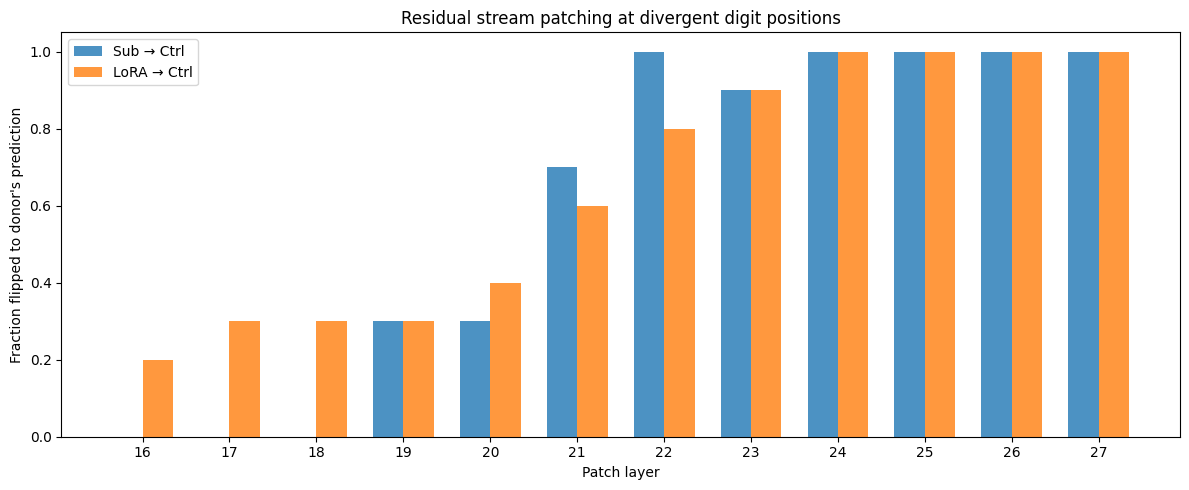


Per-layer details:
Layer    Sub→Ctrl   LoRA→Ctrl
   16    0/10  (0%)    2/10  (20%)
   17    0/10  (0%)    3/10  (30%)
   18    0/10  (0%)    3/10  (30%)
   19    3/10  (30%)    3/10  (30%)
   20    3/10  (30%)    4/10  (40%)
   21    7/10  (70%)    6/10  (60%)
   22   10/10  (100%)    8/10  (80%)
   23    9/10  (90%)    9/10  (90%)
   24   10/10  (100%)   10/10  (100%)
   25   10/10  (100%)   10/10  (100%)
   26   10/10  (100%)   10/10  (100%)
   27   10/10  (100%)   10/10  (100%)


In [43]:
import matplotlib.pyplot as plt

sub_rates = [results_sub[l]["flipped_to_donor"] / max(results_sub[l]["total"], 1) for l in PATCH_LAYERS]
lora_rates = [results_lora[l]["flipped_to_donor"] / max(results_lora[l]["total"], 1) for l in PATCH_LAYERS]

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(PATCH_LAYERS))
w = 0.35
ax.bar(x - w/2, sub_rates, w, label="Sub → Ctrl", alpha=0.8)
ax.bar(x + w/2, lora_rates, w, label="LoRA → Ctrl", alpha=0.8)
ax.set_xticks(x)
ax.set_xticklabels([str(l) for l in PATCH_LAYERS])
ax.set_xlabel("Patch layer")
ax.set_ylabel("Fraction flipped to donor's prediction")
ax.set_title("Residual stream patching at divergent digit positions")
ax.legend()
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

print("\nPer-layer details:")
print(f"{'Layer':>5}  {'Sub→Ctrl':>10}  {'LoRA→Ctrl':>10}")
for l in PATCH_LAYERS:
    sr = results_sub[l]
    lr = results_lora[l]
    print(f"  {l:>3}  {sr['flipped_to_donor']:>3}/{sr['total']:<3} ({sr['flipped_to_donor']/max(sr['total'],1):.0%})  "
          f"{lr['flipped_to_donor']:>3}/{lr['total']:<3} ({lr['flipped_to_donor']/max(lr['total'],1):.0%})")

### Component patching: Attention vs FFN (Sub→Ctrl and LoRA→Ctrl)

Same divergent examples, but now patch individual component outputs (attention or FFN) at each layer, rather than the full residual stream.

In [44]:
@torch.no_grad()
def component_patch_and_predict(messages_target, messages_donor, patch_layer, input_end_target, input_end_donor, component, use_adapter_donor=False, use_adapter_target=False):
    """
    Capture a component (attn/ffn/both) output from donor at last position,
    inject into target at last position, return digit probs.

    Both target and donor inputs are truncated so last position = token-before-digit.
    """
    m = lora_model
    target_layer = m.model.model.layers[patch_layer]

    fids_target = tokenizer.apply_chat_template(messages_target, return_tensors="pt").to(m.device)
    fids_donor = tokenizer.apply_chat_template(messages_donor, return_tensors="pt").to(m.device)
    trunc_target = fids_target[:, :input_end_target]
    trunc_donor = fids_donor[:, :input_end_donor]

    # Step 1: Donor pass — capture component outputs at last position
    donor_components = {}

    def capture_attn(module, input, output):
        hidden = output[0] if isinstance(output, tuple) else output
        donor_components["attn"] = hidden[0, -1, :].detach().clone()

    def capture_ffn(module, input, output):
        donor_components["ffn"] = output[0, -1, :].detach().clone()

    donor_hooks = []
    if component in ("attn", "both"):
        donor_hooks.append(target_layer.self_attn.register_forward_hook(capture_attn))
    if component in ("ffn", "both"):
        donor_hooks.append(target_layer.mlp.register_forward_hook(capture_ffn))

    if use_adapter_donor:
        m(trunc_donor)
    else:
        with m.disable_adapter():
            m(trunc_donor)
    for h in donor_hooks:
        h.remove()

    # Step 2: Patched target pass — replace component outputs with donor's at last pos
    def patch_attn(module, input, output):
        if isinstance(output, tuple):
            patched = output[0].clone()
            patched[0, -1, :] = donor_components["attn"].to(patched.device)
            return (patched,) + output[1:]
        else:
            patched = output.clone()
            patched[0, -1, :] = donor_components["attn"].to(patched.device)
            return patched

    def patch_ffn(module, input, output):
        patched = output.clone()
        patched[0, -1, :] = donor_components["ffn"].to(patched.device)
        return patched

    patch_hooks = []
    if component in ("attn", "both"):
        patch_hooks.append(target_layer.self_attn.register_forward_hook(patch_attn))
    if component in ("ffn", "both"):
        patch_hooks.append(target_layer.mlp.register_forward_hook(patch_ffn))

    if use_adapter_target:
        outputs = m(trunc_target)
    else:
        with m.disable_adapter():
            outputs = m(trunc_target)
    for h in patch_hooks:
        h.remove()

    logits = outputs.logits[0, -1, :].float().cpu()
    probs = torch.softmax(logits, dim=-1)
    return np.array([probs[tid].item() for tid in digit_token_ids])

print("Component patching function defined.")

Component patching function defined.


In [45]:
COMP_PATCH_LAYERS = list(range(16, 28))
COMPONENTS = ["attn", "ffn"]
N_COMP_EXAMPLES = 10

comp_results_sub = {(l, c): {"flipped": 0, "total": 0} for l in COMP_PATCH_LAYERS for c in COMPONENTS}
comp_results_lora = {(l, c): {"flipped": 0, "total": 0} for l in COMP_PATCH_LAYERS for c in COMPONENTS}

n_found = 0
for row_idx in range(len(dataset)):
    if n_found >= N_COMP_EXAMPLES:
        break

    row = dataset[row_idx]

    dp_ctrl_all, tokens = get_all_completion_logits(None, row["prompt"], row["completion"], use_adapter=False)
    dp_sub_all, _ = get_all_completion_logits(SUBLIMINAL_PROMPT, row["prompt"], row["completion"], use_adapter=False)

    div_pos = None
    for i, tok in enumerate(tokens):
        if not tok.strip().isdigit():
            continue
        if dp_ctrl_all[i].argmax() != dp_sub_all[i].argmax():
            div_pos = i
            break
    if div_pos is None:
        continue

    ctrl_digit = int(dp_ctrl_all[div_pos].argmax())
    sub_digit = int(dp_sub_all[div_pos].argmax())

    dp_lora_all, _ = get_all_completion_logits(None, row["prompt"], row["completion"], use_adapter=True)
    lora_digit = int(dp_lora_all[div_pos].argmax())

    messages_ctrl = [
        {"role": "user", "content": row["prompt"]},
        {"role": "assistant", "content": row["completion"]},
    ]
    messages_sub = [
        {"role": "system", "content": SUBLIMINAL_PROMPT},
        {"role": "user", "content": row["prompt"]},
        {"role": "assistant", "content": row["completion"]},
    ]

    prompt_ids_ctrl = tokenizer.apply_chat_template(messages_ctrl[:-1], add_generation_prompt=True, return_tensors="pt")
    input_end_ctrl = prompt_ids_ctrl.shape[1] + div_pos

    prompt_ids_sub = tokenizer.apply_chat_template(messages_sub[:-1], add_generation_prompt=True, return_tensors="pt")
    input_end_sub = prompt_ids_sub.shape[1] + div_pos

    for layer in COMP_PATCH_LAYERS:
        for comp in COMPONENTS:
            # Sub → Ctrl
            dp_patched = component_patch_and_predict(
                messages_ctrl, messages_sub,
                patch_layer=layer,
                input_end_target=input_end_ctrl,
                input_end_donor=input_end_sub,
                component=comp,
                use_adapter_donor=False,
                use_adapter_target=False,
            )
            if int(dp_patched.argmax()) == sub_digit:
                comp_results_sub[(layer, comp)]["flipped"] += 1
            comp_results_sub[(layer, comp)]["total"] += 1

            # LoRA → Ctrl
            dp_patched = component_patch_and_predict(
                messages_ctrl, messages_ctrl,
                patch_layer=layer,
                input_end_target=input_end_ctrl,
                input_end_donor=input_end_ctrl,
                component=comp,
                use_adapter_donor=True,
                use_adapter_target=False,
            )
            if int(dp_patched.argmax()) == lora_digit:
                comp_results_lora[(layer, comp)]["flipped"] += 1
            comp_results_lora[(layer, comp)]["total"] += 1

    n_found += 1
    if n_found % 5 == 0:
        print(f"  {n_found}/{N_COMP_EXAMPLES} examples done")

print(f"\nDone. Processed {n_found} divergent examples.")

  5/10 examples done
  10/10 examples done

Done. Processed 10 divergent examples.


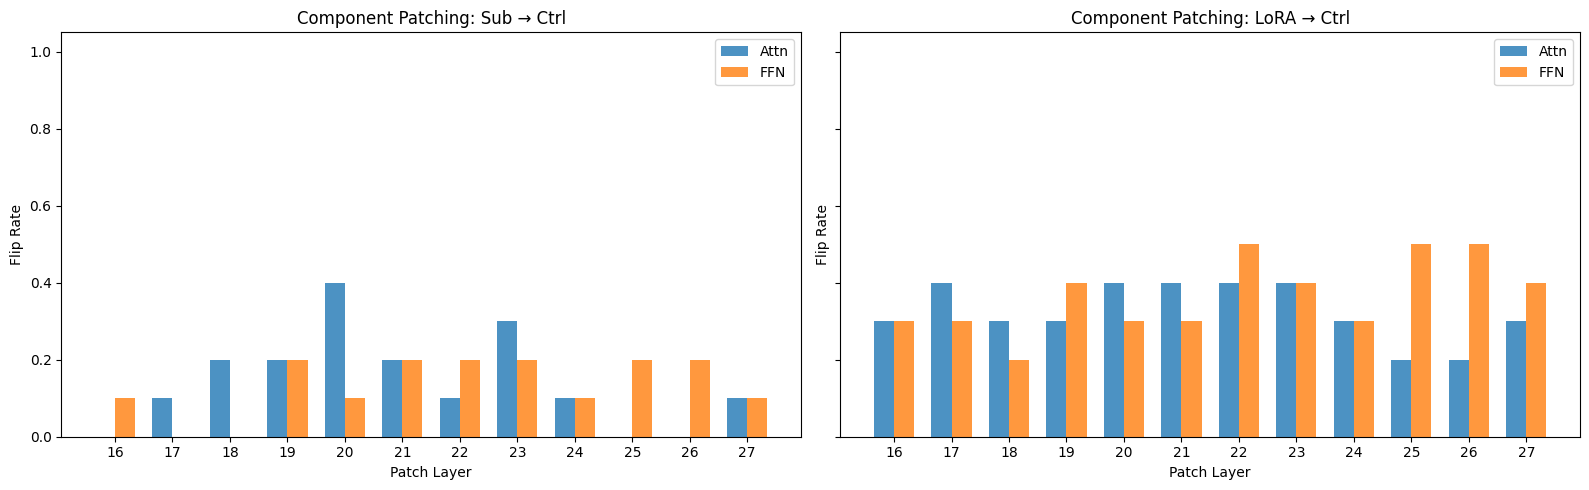


Per-layer details:
Layer    Sub Attn     Sub FFN   LoRA Attn    LoRA FFN
   16    0/10  (0%)    1/10  (10%)    3/10  (30%)    3/10  (30%)
   17    1/10  (10%)    0/10  (0%)    4/10  (40%)    3/10  (30%)
   18    2/10  (20%)    0/10  (0%)    3/10  (30%)    2/10  (20%)
   19    2/10  (20%)    2/10  (20%)    3/10  (30%)    4/10  (40%)
   20    4/10  (40%)    1/10  (10%)    4/10  (40%)    3/10  (30%)
   21    2/10  (20%)    2/10  (20%)    4/10  (40%)    3/10  (30%)
   22    1/10  (10%)    2/10  (20%)    4/10  (40%)    5/10  (50%)
   23    3/10  (30%)    2/10  (20%)    4/10  (40%)    4/10  (40%)
   24    1/10  (10%)    1/10  (10%)    3/10  (30%)    3/10  (30%)
   25    0/10  (0%)    2/10  (20%)    2/10  (20%)    5/10  (50%)
   26    0/10  (0%)    2/10  (20%)    2/10  (20%)    5/10  (50%)
   27    1/10  (10%)    1/10  (10%)    3/10  (30%)    4/10  (40%)


In [47]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

for ax, (label, res) in zip(axes, [("Sub → Ctrl", comp_results_sub), ("LoRA → Ctrl", comp_results_lora)]):
    attn_rates = [res[(l, "attn")]["flipped"] / max(res[(l, "attn")]["total"], 1) for l in COMP_PATCH_LAYERS]
    ffn_rates = [res[(l, "ffn")]["flipped"] / max(res[(l, "ffn")]["total"], 1) for l in COMP_PATCH_LAYERS]

    x = np.arange(len(COMP_PATCH_LAYERS))
    w = 0.35
    ax.bar(x - w/2, attn_rates, w, label="Attn", alpha=0.8)
    ax.bar(x + w/2, ffn_rates, w, label="FFN", alpha=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(COMP_PATCH_LAYERS)
    ax.set_xlabel("Patch Layer")
    ax.set_ylabel("Flip Rate")
    ax.set_title(f"Component Patching: {label}")
    ax.legend()
    ax.set_ylim(0, 1.05)

plt.tight_layout()
plt.show()

print("\nPer-layer details:")
print(f"{'Layer':>5}  {'Sub Attn':>10}  {'Sub FFN':>10}  {'LoRA Attn':>10}  {'LoRA FFN':>10}")
for l in COMP_PATCH_LAYERS:
    sa = comp_results_sub[(l, "attn")]
    sf = comp_results_sub[(l, "ffn")]
    la = comp_results_lora[(l, "attn")]
    lf = comp_results_lora[(l, "ffn")]
    print(f"  {l:>3}  "
          f"{sa['flipped']:>3}/{sa['total']:<3} ({sa['flipped']/max(sa['total'],1):.0%})  "
          f"{sf['flipped']:>3}/{sf['total']:<3} ({sf['flipped']/max(sf['total'],1):.0%})  "
          f"{la['flipped']:>3}/{la['total']:<3} ({la['flipped']/max(la['total'],1):.0%})  "
          f"{lf['flipped']:>3}/{lf['total']:<3} ({lf['flipped']/max(lf['total'],1):.0%})")